# Семинары 3–4: свёртки, оптимизация и adversarial examples

- `nn.Conv2d`: https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
- `F.unfold`: https://pytorch.org/docs/stable/generated/torch.nn.Unfold.html
- `torch.optim`: https://pytorch.org/docs/stable/optim.html
- Goodfellow et al., 2014 (FGSM): https://arxiv.org/abs/1412.6572
- Madry et al., 2017 (PGD): https://arxiv.org/abs/1706.06083

## План

**Семинар 3. Свёртки, receptive field, активации**

1. Картинки как тензоры: $(B, C, H, W)$
2. Свёртка: один элемент руками, cross-correlation vs convolution
3. Размер выхода: kernel size, stride, padding, dilation
4. Каналы, число параметров, свёртка как матрица
5. \*Свёртка через FFT
6. `groups`, depthwise и 1×1 свёртки
7. Строительный блок CNN: pooling, `BatchNorm2d`, порядок слоёв
8. Receptive field: рекурсия
9. Функции активации: saturation, dead ReLU, gradient flow, \*gated FFN (SwiGLU, GEGLU)

**Семинар 4. Оптимизаторы, residual connections, adversarial examples**

10. SGD, Momentum, Adam, AdamW, Lion, \*Muon, \*Shampoo; анимация сходимости
11. Residual connection
12. Маленькая CNN на FashionMNIST
13. Adversarial examples; градиент по входу
14. FGSM
15. Accuracy от $\varepsilon$
16. PGD
17. FGSM vs PGD
18. \*Атака одним пикселем ($L_0$)
19. \*Adversarial training

In [1]:
# !pip install torch torchvision matplotlib
import copy
import itertools
import math
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.0+cu126
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

---
# Семинар 3. Свёртки, receptive field, активации

# 1. Картинки как тензоры

$$(B, C, H, W) = (\text{batch}, \text{channels}, \text{height}, \text{width})$$

В numpy / PIL / matplotlib каналы обычно последние: $(H, W, C)$.

In [3]:
from matplotlib import cbook

photo = plt.imread(cbook.get_sample_data('grace_hopper.jpg', asfileobj=False))   # numpy (H, W, 3), uint8
photo_t = torch.from_numpy(photo).permute(2, 0, 1).float() / 255                   # (C, H, W), float в [0, 1]
photo.shape, photo.dtype, photo_t.shape, photo_t.dtype

C:\Users\vit\AppData\Local\Temp\ipykernel_24724\726147351.py:4: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  photo_t = torch.from_numpy(photo).permute(2, 0, 1).float() / 255                   # (C, H, W), float в [0, 1]


((600, 512, 3), dtype('uint8'), torch.Size([3, 600, 512]), torch.float32)

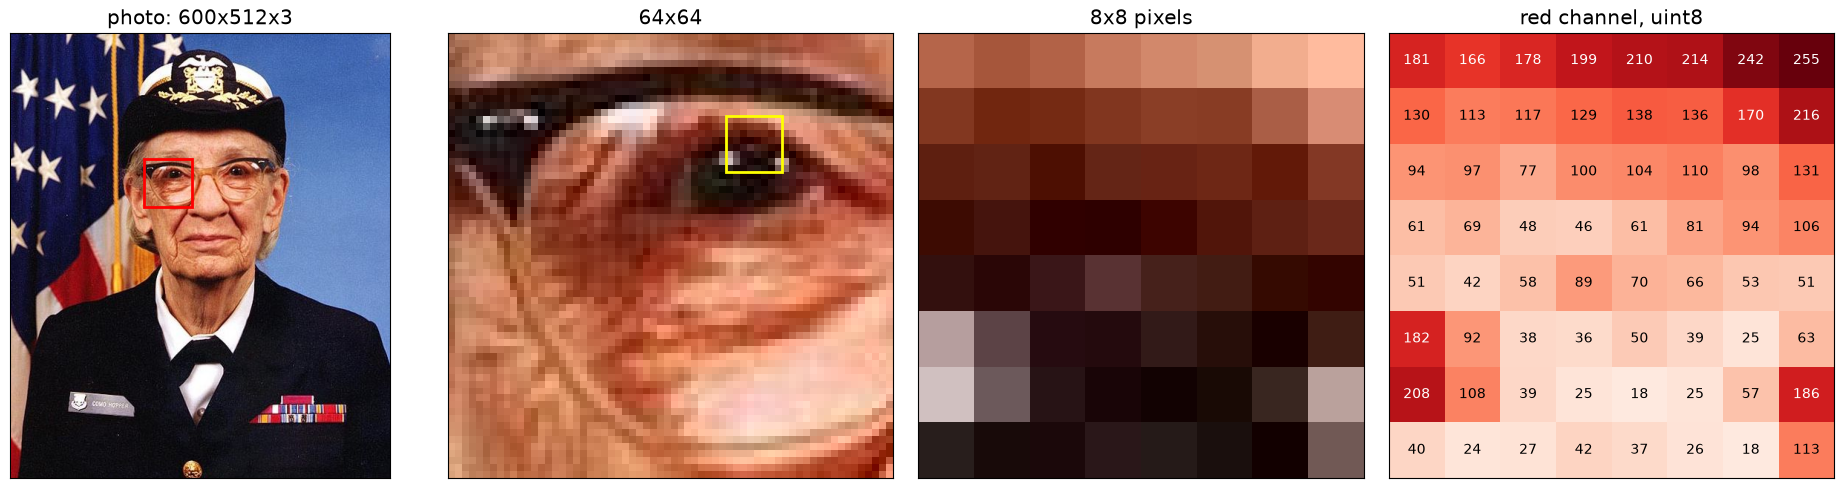

In [5]:
eye_r, eye_c, zoom = 170, 180, 64               # фрагмент 64x64 вокруг глаза
px_r, px_c, tiny = eye_r + 12, eye_c + 40, 8    # внутри него — 8x8 пикселей

fig, axes = plt.subplots(1, 4, figsize=(19, 5))
axes[0].imshow(photo)
axes[0].add_patch(plt.Rectangle((eye_c, eye_r), zoom, zoom, fill=False, edgecolor='red', linewidth=2))
axes[0].set_title(f'photo: {photo.shape[0]}x{photo.shape[1]}x{photo.shape[2]}')
axes[1].imshow(photo[eye_r:eye_r + zoom, eye_c:eye_c + zoom])
axes[1].add_patch(plt.Rectangle((px_c - eye_c - 0.5, px_r - eye_r - 0.5), tiny, tiny,
                                fill=False, edgecolor='yellow', linewidth=2))
axes[1].set_title(f'{zoom}x{zoom}')
axes[2].imshow(photo[px_r:px_r + tiny, px_c:px_c + tiny])
axes[2].set_title(f'{tiny}x{tiny} pixels')
red = photo[px_r:px_r + tiny, px_c:px_c + tiny, 0]
axes[3].imshow(red, cmap='Reds', vmin=0, vmax=255)
for r in range(tiny):
    for c in range(tiny):
        axes[3].text(c, r, str(red[r, c]), ha='center', va='center', fontsize=10,
                     color='white' if red[r, c] > 150 else 'black')
axes[3].set_title('red channel, uint8')
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [8]:
photo_t[:, px_r:px_r + 3, px_c:px_c + 3]   # (C, 3, 3): три канала, те же пиксели / 255

tensor([[[0.7098, 0.6510, 0.6980],
         [0.5098, 0.4431, 0.4588],
         [0.3686, 0.3804, 0.3020]],

        [[0.3961, 0.3373, 0.3843],
         [0.2157, 0.1490, 0.1647],
         [0.1216, 0.1373, 0.0588]],

        [[0.2902, 0.2314, 0.2784],
         [0.1255, 0.0588, 0.0745],
         [0.0627, 0.0784, 0.0078]]])

In [7]:
x = torch.rand(8, 3, 32, 32)   # 8 RGB-картинок 32x32
print(x.shape)                 # (B, C, H, W)
print(x[0].shape)              # одна картинка (C, H, W)
print(x[0, 0].shape)           # один канал (H, W)
print(x[:, :, 10, 20].shape)   # пиксель (10, 20): (B, C)

torch.Size([8, 3, 32, 32])
torch.Size([3, 32, 32])
torch.Size([32, 32])
torch.Size([8, 3])


In [9]:
x[0].permute(1, 2, 0).shape   # (C, H, W) -> (H, W, C) для plt.imshow

torch.Size([32, 32, 3])

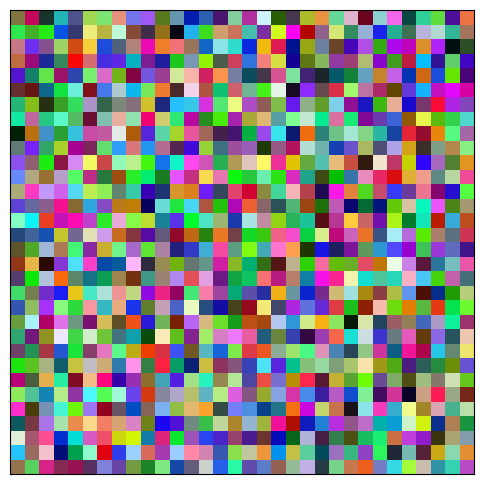

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(19, 5))
ax.imshow(x[0].permute(1, 2, 0))
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

In [11]:
conv = nn.Conv2d(3, 4, kernel_size=3)
conv(x).shape, conv(x[0]).shape   # batch-ось можно опустить

(torch.Size([8, 4, 30, 30]), torch.Size([4, 30, 30]))

---
# 2. Что делает свёртка

Один канал, ядро $3 \times 3$, stride = 1, padding = 0:
$$y[i, j] = \sum_{u=0}^{k-1}\sum_{v=0}^{k-1} x[i + u,\; j + v]\cdot w[u, v] + b.$$

Ядро скользит по входу, в каждой позиции считается скалярное произведение ядра и патча. Веса $w$ общие для всех позиций (weight sharing).

![conv sliding](figures/conv_sliding.gif)

In [13]:
torch.manual_seed(0)
x_small = torch.randint(0, 10, (5, 5)).float()
w_small = torch.tensor([[1., 0., -1.],
                        [2., 0., -2.],
                        [1., 0., -1.]])   # ядро Собеля
x_small

tensor([[4., 9., 3., 0., 3.],
        [9., 7., 3., 7., 3.],
        [1., 6., 6., 9., 8.],
        [6., 6., 8., 4., 3.],
        [6., 9., 1., 4., 4.]])

In [14]:
i, j = 1, 1
patch = x_small[i:i + 3, j:j + 3]
y_ij = (patch * w_small).sum()
y_ij

tensor(-4.)

In [19]:
# F.conv2d ждёт x: (B, C_in, H, W), weight: (C_out, C_in, kH, kW)
y_small = F.conv2d(x_small[None, None], w_small[None, None])[0, 0]
assert y_small[i, j] == y_ij
y_small

tensor([[ 8.,  6., -2.],
        [-6., -4.,  1.],
        [-4.,  6.,  5.]])

In [23]:
def show_matrix(ax, M, title, highlight=None, cmap='Blues'):
    # highlight = (row, col, height, width)
    M = M.detach().cpu()
    vmax = M.abs().max()
    ax.imshow(M, cmap=cmap, vmin=-vmax if cmap == 'coolwarm' else M.min(), vmax=vmax, alpha=0.65)
    for r in range(M.shape[0]):
        for c in range(M.shape[1]):
            ax.text(c, r, f'{M[r, c].item():.0f}', ha='center', va='center', fontsize=14)
    if highlight is not None:
        r0, c0, h, w = highlight
        ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), w, h, fill=False, edgecolor='red', linewidth=3))
    ax.set_title(title)
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

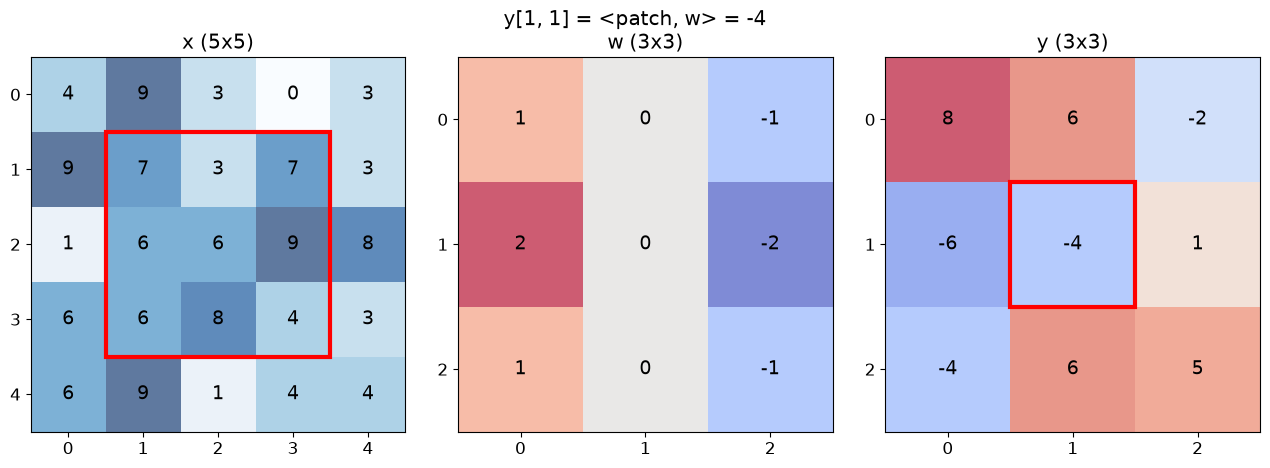

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
show_matrix(axes[0], x_small, 'x (5x5)', highlight=(i, j, 3, 3))
show_matrix(axes[1], w_small, 'w (3x3)', cmap='coolwarm')
show_matrix(axes[2], y_small, 'y (3x3)', highlight=(i, j, 1, 1), cmap='coolwarm')
plt.suptitle(f'y[{i}, {j}] = <patch, w> = {y_ij.item():.0f}')
plt.tight_layout()
plt.show()

### Cross-correlation vs convolution

Математическая свёртка переворачивает ядро:
$$(x * w)[i, j] = \sum_{u,v} x[i - u,\, j - v]\; w[u, v].$$

`nn.Conv2d` / `F.conv2d` ядро не переворачивают — это cross-correlation. Для обучаемых весов разницы нет: сеть выучит перевёрнутое ядро. Важно, только когда переносим фиксированный фильтр из обработки сигналов.

In [25]:
w_flipped = torch.flip(w_small, dims=(0, 1))
true_conv = F.conv2d(x_small[None, None], w_flipped[None, None])[0, 0]
assert torch.equal(true_conv, -y_small)   # Собель антисимметричен: переворот = смена знака
true_conv

tensor([[-8., -6.,  2.],
        [ 6.,  4., -1.],
        [ 4., -6., -5.]])

### Фильтры Собеля на картинке

Каждое ядро реагирует на свой локальный паттерн: Sobel x — на вертикальные границы, Sobel y — на горизонтальные. Так выглядят фильтры первого слоя обученной CNN.

In [26]:
yy, xx = torch.meshgrid(torch.arange(40.), torch.arange(40.), indexing='ij')
image = ((xx - 12) ** 2 + (yy - 20) ** 2 < 64).float()   # круг
image[8:32, 24:34] = 1.0                                   # прямоугольник
image = image[None, None]                                  # (1, 1, 40, 40)

In [27]:
kernels = torch.stack([w_small, w_small.T])[:, None]   # (C_out=2, C_in=1, 3, 3)
edges = F.conv2d(image, kernels, padding=1)            # (1, 2, 40, 40)
magnitude = edges.pow(2).sum(dim=1).sqrt()[0]
edges.shape

torch.Size([1, 2, 40, 40])

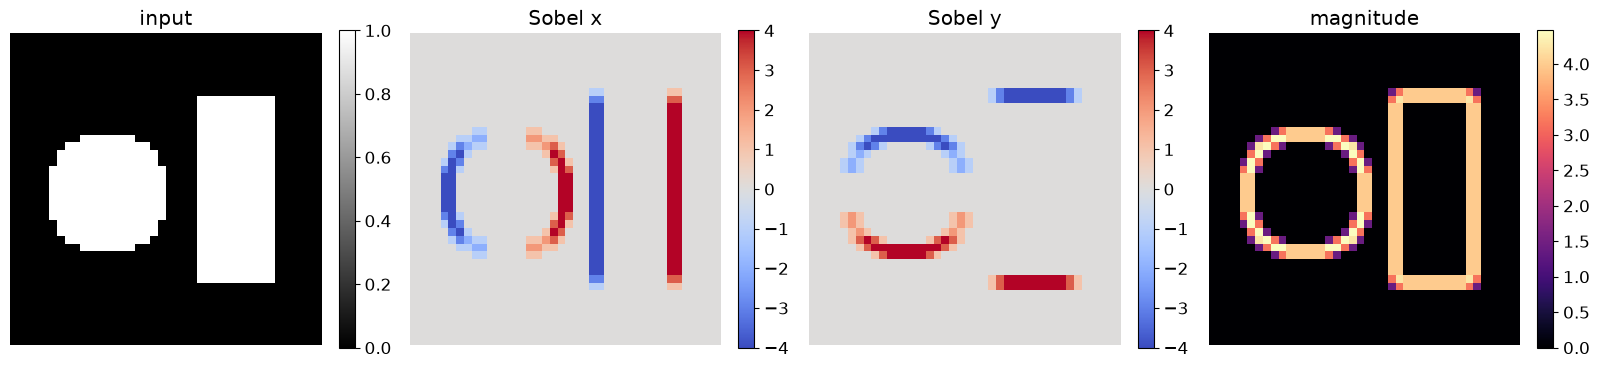

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
panels = [(image[0, 0], 'input', 'gray'),
          (edges[0, 0], 'Sobel x', 'coolwarm'),
          (edges[0, 1], 'Sobel y', 'coolwarm'),
          (magnitude, 'magnitude', 'magma')]
for ax, (img, title, cmap) in zip(axes, panels):
    im = ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### Sobel на видео

![Sobel video](figures/sobel_video.gif)

Кадры видео — это batch $(T, 1, H, W)$: одна `F.conv2d` с теми же ядрами обрабатывает все 48 кадров сразу

In [29]:
# equivariance к сдвигу: сдвинули вход -> отклик сдвинулся так же (вдали от краёв)
shifted = torch.roll(image, shifts=(0, 5), dims=(-2, -1))
out_shifted = F.conv2d(shifted, kernels, padding=1)
out_then_shift = torch.roll(F.conv2d(image, kernels, padding=1), shifts=(0, 5), dims=(-2, -1))
torch.allclose(out_shifted[..., 2:-2, 7:-2], out_then_shift[..., 2:-2, 7:-2])

True

---
# 3. Размер выхода

- kernel size $k$, stride $s$, padding $p$, dilation $d$
- эффективный размер ядра: $k^{\mathrm{eff}} = 1 + d(k-1)$

$$
H_{\mathrm{out}} = \left\lfloor \frac{H_{\mathrm{in}} + 2p - d(k-1) - 1}{s} + 1 \right\rfloor,
$$
аналогично по ширине.

Интуиция: после паддинга длина $H_{\mathrm{in}} + 2p$, окно занимает $k^{\mathrm{eff}}$ пикселей, и мы считаем, сколько раз окно с шагом $s$ помещается внутрь (плюс одна начальная позиция).

![stride, padding, dilation](figures/conv_params.svg)

Ядро $3 \times 3$ с dilation $d$ трогает те же 9 пикселей, но растянутых на окно $k^{\mathrm{eff}} \times k^{\mathrm{eff}}$: параметров столько же, поле зрения больше.

<table><tr><td align="center"><img src="figures/conv_arithmetic/no_padding_no_strides.gif" width="200"><br>padding = 0, stride = 1</td><td align="center"><img src="figures/conv_arithmetic/same_padding_no_strides.gif" width="200"><br>padding = 1 ('same')</td><td align="center"><img src="figures/conv_arithmetic/full_padding_no_strides.gif" width="200"><br>padding = 2 ('full')</td></tr><tr><td align="center"><img src="figures/conv_arithmetic/no_padding_strides.gif" width="200"><br>stride = 2</td><td align="center"><img src="figures/conv_arithmetic/padding_strides.gif" width="200"><br>padding = 1, stride = 2</td><td align="center"><img src="figures/conv_arithmetic/dilation.gif" width="200"><br>dilation = 2</td></tr></table>

Ядро $3 \times 3$; синий — вход, бирюзовый — выход. Анимации: V. Dumoulin, F. Visin, *A guide to convolution arithmetic for deep learning*, arXiv:1603.07285; [github.com/vdumoulin/conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic), MIT License.

In [43]:
def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


print(conv_output_size(32, 3))                        # 30
print(conv_output_size(32, 3, padding=1))             # 32
print(conv_output_size(32, 3, stride=2, padding=1))   # 16
print(conv_output_size(32, 3, dilation=2))            # 28: k_eff = 5

30
32
16
28


In [33]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)


conv_output_shape((17, 24), kernel_size=(3, 5), stride=(2, 1), padding=(1, 2), dilation=(1, 2))

(9, 20)

In [34]:
x = torch.randn(1, 1, 17, 24)
cfg = dict(kernel_size=(3, 5), stride=(2, 1), padding=(1, 2), dilation=(1, 2))
nn.Conv2d(1, 1, **cfg)(x).shape

torch.Size([1, 1, 9, 20])

In [35]:
# Формула против nn.Conv2d на сетке параметров
n_checked = 0
for k, s, p, d in itertools.product([1, 2, 3, 5], [1, 2, 3], [0, 1, 2], [1, 2, 3]):
    if conv_output_size(17, k, s, p, d) <= 0:
        continue
    out = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p, dilation=d)(x)
    assert out.shape[-2:] == conv_output_shape((17, 24), k, s, p, d), (k, s, p, d)
    n_checked += 1
n_checked

108

### `padding='same'` и `padding_mode`

`padding='same'` подбирает $p$ так, чтобы $H_{\mathrm{out}} = H_{\mathrm{in}}$; для stride > 1 не поддерживается. `padding_mode` задаёт, чем заполнять края: нулями, отражением, повтором.

In [36]:
x = torch.randn(1, 1, 17, 24)
for kwargs in [dict(kernel_size=5, padding='same'),
               dict(kernel_size=3, dilation=3, padding='same'),
               dict(kernel_size=3, padding=1, padding_mode='reflect')]:
    print(kwargs, '->', tuple(nn.Conv2d(1, 1, **kwargs)(x).shape))

{'kernel_size': 5, 'padding': 'same'} -> (1, 1, 17, 24)
{'kernel_size': 3, 'dilation': 3, 'padding': 'same'} -> (1, 1, 17, 24)
{'kernel_size': 3, 'padding': 1, 'padding_mode': 'reflect'} -> (1, 1, 17, 24)


In [37]:
try:
    nn.Conv2d(1, 1, kernel_size=3, stride=2, padding='same')
except ValueError as e:
    print('ValueError:', e)

ValueError: padding='same' is not supported for strided convolutions


---
# 4. Каналы и число параметров

$$y[o, i, j] = b[o] + \sum_{c=1}^{C_{\text{in}}} \sum_{u, v} x[c, i+u, j+v]\; w[o, c, u, v]$$

$$\text{weight}: (C_{\text{out}},\; C_{\text{in}}/g,\; k_h,\; k_w), \qquad \text{bias}: (C_{\text{out}})$$

$$
\#\text{params} = C_{\text{out}} \left( \frac{C_{\text{in}}}{g} k_h k_w + \mathbf{1}_{\text{bias}} \right)
$$

Каждый выходной канал смотрит на **все** входные каналы: это сумма $C_{\text{in}}$ двумерных свёрток плюс bias.

![channels](figures/conv_channels.svg)

![conv multichannel](figures/conv_multichannel.gif)

In [44]:
conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
conv.weight.shape, conv.bias.shape

(torch.Size([16, 3, 3, 3]), torch.Size([16]))

In [45]:
# выходной канал o = сумма одноканальных свёрток по входным каналам + bias
x = torch.randn(2, 3, 10, 10)
o = 5
y_manual = sum(F.conv2d(x[:, c:c + 1], conv.weight[o:o + 1, c:c + 1]) for c in range(3)) + conv.bias[o]
torch.allclose(conv(x)[:, o:o + 1], y_manual, atol=1e-6)

True

In [46]:
def count_conv_parameters(in_channels, out_channels, kernel_size, groups=1, bias=True):
    kh, kw = pair(kernel_size)
    return out_channels * (in_channels // groups * kh * kw + int(bias))


count_conv_parameters(3, 16, 3), sum(p.numel() for p in conv.parameters())

(448, 448)

In [49]:
configs = [
    dict(in_channels=3, out_channels=16, kernel_size=3, bias=False),
    dict(in_channels=64, out_channels=128, kernel_size=3),
    dict(in_channels=64, out_channels=128, kernel_size=(1, 7)),
    dict(in_channels=3, out_channels=64, kernel_size=7),
]
for cfg in configs:
    n_params = count_conv_parameters(**cfg)
    assert n_params == sum(p.numel() for p in nn.Conv2d(**cfg).parameters())
    print(f'{str(cfg):<72} {n_params:>7}')

{'in_channels': 3, 'out_channels': 16, 'kernel_size': 3, 'bias': False}      432
{'in_channels': 64, 'out_channels': 128, 'kernel_size': 3}                 73856
{'in_channels': 64, 'out_channels': 128, 'kernel_size': (1, 7)}            57472
{'in_channels': 3, 'out_channels': 64, 'kernel_size': 7}                    9472


### Conv2d vs Linear на том же отображении $3 \times 32 \times 32 \to 16 \times 32 \times 32$

In [50]:
n_conv = count_conv_parameters(3, 16, 3)
n_linear = (3 * 32 * 32) * (16 * 32 * 32) + 16 * 32 * 32
print(f'Conv2d: {n_conv:>12,}')
print(f'Linear: {n_linear:>12,}  ({n_linear / n_conv:,.0f}x)')

Conv2d:          448
Linear:   50,348,032  (112,384x)


Экономия даёт два свойства: **locality** (выход зависит от маленькой окрестности) и **weight sharing** (одно ядро во всех позициях). Поэтому число параметров свёртки не зависит от $H, W$.

### Свёртка как матрица

Свёртка линейна по $x$, то есть это `Linear` с особой матрицей:
$$\mathrm{vec}(y) = M\,\mathrm{vec}(x), \qquad M \in \mathbb R^{H_{\mathrm{out}} W_{\mathrm{out}} \times H W}.$$
Якобиан линейной функции — это и есть её матрица, достанем $M$ через autograd:

In [51]:
conv_sobel = lambda t: F.conv2d(t, w_small[None, None])
M_conv = torch.autograd.functional.jacobian(conv_sobel, x_small[None, None]).reshape(9, 25)   # (H_out*W_out, H*W)
assert torch.allclose(M_conv @ x_small.flatten(), y_small.flatten())
M_conv.shape, (M_conv != 0).sum().item()

(torch.Size([9, 25]), 54)

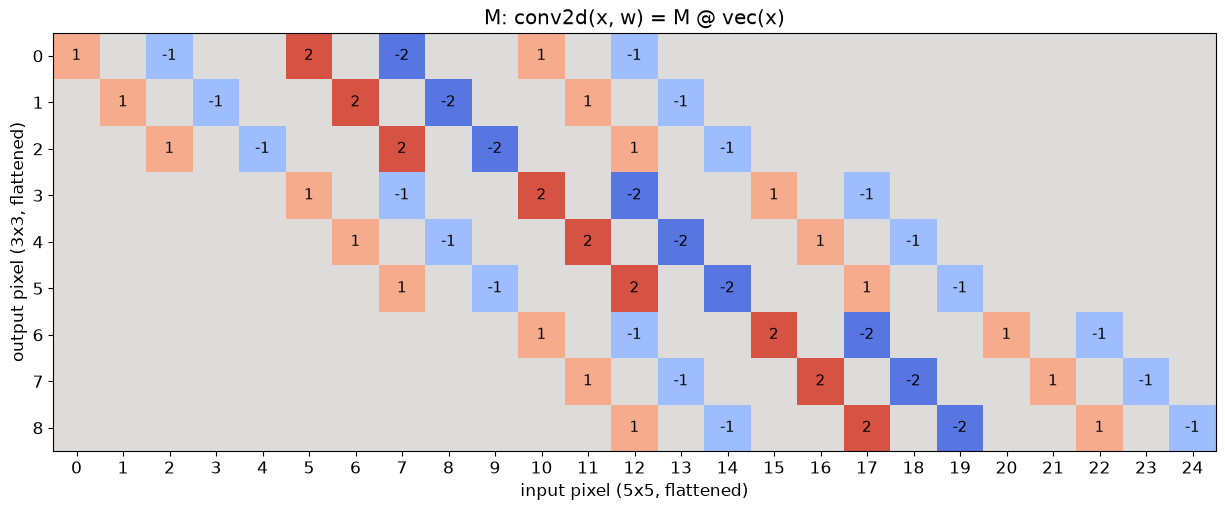

In [52]:
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.imshow(M_conv, cmap='coolwarm', vmin=-2.5, vmax=2.5)
for r, c in (M_conv != 0).nonzero().tolist():
    ax.text(c, r, f'{M_conv[r, c]:.0f}', ha='center', va='center', fontsize=11)
ax.set_xticks(range(25))
ax.set_yticks(range(9))
ax.set_xlabel('input pixel (5x5, flattened)')
ax.set_ylabel('output pixel (3x3, flattened)')
ax.set_title('M: conv2d(x, w) = M @ vec(x)')
plt.show()

В каждой строке одни и те же числа ядра, сдвинутые (**weight sharing**), остальное — нули (**locality**): из 225 элементов ненулевых 54, а хранятся 9 весов.

### Градиент по входу — transposed convolution

$$\nabla_x \big\langle \mathrm{conv}(x),\, g \big\rangle = M^\top g = \texttt{conv\_transpose2d}(g, w)$$

In [53]:
torch.manual_seed(0)
g = torch.randn(1, 1, 3, 3)                        # dL/dy
x_req = x_small[None, None].clone().requires_grad_(True)
grad_x, = torch.autograd.grad((conv_sobel(x_req) * g).sum(), x_req)

via_M = (M_conv.T @ g.flatten()).reshape(1, 1, 5, 5)
via_transpose = F.conv_transpose2d(g, w_small[None, None])
torch.allclose(grad_x, via_M), torch.allclose(grad_x, via_transpose)

(True, True)

Backward свёртки по входу — тоже свёртка, транспонированная. Через неё пойдёт $\nabla_x L$ в adversarial-атаках (раздел 13). `nn.ConvTranspose2d` — слой, который умножает на $M^\top$: upsampling в декодерах U-Net и GAN.

---
# 5\*. Свёртка через FFT

Теорема о свёртке: в частотной области свёртка — поэлементное произведение,
$$\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w).$$

- DFT считает **циклическую** свёртку: чтобы края не «заворачивались», дополняем нулями до $H + k - 1$;
- `F.conv2d` — cross-correlation, поэтому ядро переворачиваем;
- сумма по входным каналам остаётся суммой и в частотной области (линейность).

Стоимость на пару каналов: напрямую $O(H W k^2)$, через FFT $O(H W \log (H W))$ — не зависит от $k$.

In [54]:
def fast_len(n):
    # ближайшее n' >= n только с множителями 2, 3, 5: на таких длинах FFT быстрый
    while True:
        m = n
        for p in (2, 3, 5):
            while m % p == 0:
                m //= p
        if m == 1:
            return n
        n += 1


def conv2d_fft(x, weight):
    # x: (B, C_in, H, W), weight: (C_out, C_in, kH, kW); stride = 1, padding = 0
    H, W = x.shape[-2:]
    kh, kw = weight.shape[-2:]
    size = (fast_len(H + kh - 1), fast_len(W + kw - 1))   # >= H + k - 1: без циклического «заворота»
    X = torch.fft.rfft2(x, s=size)                     # (B, C_in, H', W'//2 + 1), complex
    K = torch.fft.rfft2(weight.flip(-2, -1), s=size)   # переворот ядра: cross-correlation
    Y = torch.einsum('bchw,ochw->bohw', X, K)          # произведение + сумма по каналам
    y_full = torch.fft.irfft2(Y, s=size)               # полная линейная свёртка
    return y_full[..., kh - 1:H, kw - 1:W]             # 'valid' часть = F.conv2d без padding

In [55]:
torch.manual_seed(0)
x_t, w_t = torch.randn(2, 3, 32, 40), torch.randn(4, 3, 7, 5)
out_fft = conv2d_fft(x_t, w_t)
assert torch.allclose(out_fft, F.conv2d(x_t, w_t), atol=1e-4)
out_fft.shape

torch.Size([2, 4, 26, 36])

In [56]:
# время на этой машине: FFT выигрывает на больших ядрах
x_big = torch.randn(1, 4, 256, 256)
print(f'{"k":>4}{"F.conv2d, ms":>15}{"FFT, ms":>10}')
for k in [3, 7, 15, 31, 63]:
    w_big = torch.randn(4, 4, k, k)
    t_direct = min(timeit.repeat(lambda: F.conv2d(x_big, w_big), number=1, repeat=3))
    t_fft = min(timeit.repeat(lambda: conv2d_fft(x_big, w_big), number=1, repeat=3))
    print(f'{k:>4}{t_direct * 1000:>15.1f}{t_fft * 1000:>10.1f}')

   k   F.conv2d, ms   FFT, ms
   3            0.3       1.4
   7            0.9       1.5
  15            3.1       1.5
  31            8.3       0.8
  63           16.9       1.4


---
# 6. `groups`, depthwise и 1×1 свёртки

## 6.1 `groups`

- `groups=1` — обычная свёртка
- `1 < groups < C_in` — grouped convolution
- `groups=C_in` — depthwise

`groups = g` делит входные и выходные каналы на $g$ групп; группа выходов смотрит **только** на свою группу входов. $C_{\text{in}}$ и $C_{\text{out}}$ должны делиться на $g$:
$$
x = \big[x^{(1)}, \dots, x^{(g)}\big], \quad x^{(\gamma)} \in \mathbb R^{\frac{C_{\text{in}}}{g} \times H \times W}, \qquad
y^{(\gamma)} = \mathrm{conv}\big(x^{(\gamma)}, w^{(\gamma)}\big), \quad w^{(\gamma)} \in \mathbb R^{\frac{C_{\text{out}}}{g} \times \frac{C_{\text{in}}}{g} \times k \times k},
$$
$$
y = \big[y^{(1)}, \dots, y^{(g)}\big], \qquad \#\text{weights} = g \cdot \frac{C_{\text{out}}}{g} \cdot \frac{C_{\text{in}}}{g} \cdot k^2 = \frac{C_{\text{out}} C_{\text{in}} k^2}{g}.
$$

**Depthwise** ($g = C_{\text{in}} = C_{\text{out}} = C$): у каждого канала своё ядро $k \times k$, каналы не смешиваются:
$$y[c, i, j] = \sum_{u, v} x[c,\, i + u,\, j + v]\; w[c, u, v] + b[c], \qquad w \in \mathbb R^{C \times k \times k}.$$

![groups](figures/groups.svg)

In [57]:
C_in, C_out = 8, 12
convs = {
    'ordinary (g=1)':     nn.Conv2d(C_in, C_out, 3, groups=1),
    'grouped (g=4)':      nn.Conv2d(C_in, C_out, 3, groups=4),
    'depthwise (g=C_in)': nn.Conv2d(C_in, C_in, 3, groups=C_in),
    'pointwise 1x1':      nn.Conv2d(C_in, C_out, 1),
}

In [58]:
for name, conv in convs.items():
    n_params = sum(p.numel() for p in conv.parameters())
    assert n_params == count_conv_parameters(conv.in_channels, conv.out_channels, conv.kernel_size, conv.groups)
    print(f'{name:<20} {str(tuple(conv.weight.shape)):<16} {n_params:>5}')

ordinary (g=1)       (12, 8, 3, 3)      876
grouped (g=4)        (12, 2, 3, 3)      228
depthwise (g=C_in)   (8, 1, 3, 3)        80
pointwise 1x1        (12, 8, 1, 1)      108


In [59]:
for c_out, g in [(16, 8), (12, 8), (12, 3)]:
    try:
        nn.Conv2d(8, c_out, 3, groups=g)
        print(f'Conv2d(8, {c_out}, groups={g}): OK')
    except ValueError as e:
        print(f'Conv2d(8, {c_out}, groups={g}): {e}')

Conv2d(8, 16, groups=8): OK
Conv2d(8, 12, groups=8): out_channels must be divisible by groups
Conv2d(8, 12, groups=3): in_channels must be divisible by groups


## 6.2 1×1 свёртка

Для каждой позиции $(i, j)$ берём вектор каналов
$$z_{i,j} = x[:, i, j] \in \mathbb R^{C_{\text{in}}}$$
и применяем **одну и ту же** матрицу:
$$z'_{i,j} = W z_{i,j} + b, \qquad W \in \mathbb R^{C_{\text{out}} \times C_{\text{in}}}.$$

Это `nn.Linear` по каналам в каждой позиции: каналы смешиваются, receptive field не растёт.

In [60]:
conv1x1 = convs['pointwise 1x1']
x = torch.randn(2, C_in, 10, 10)
W1 = conv1x1.weight[:, :, 0, 0]   # (C_out, C_in)
y_einsum = torch.einsum('bchw,oc->bohw', x, W1) + conv1x1.bias[None, :, None, None]
torch.allclose(conv1x1(x), y_einsum, atol=1e-6)

True

In [61]:
linear = nn.Linear(C_in, C_out)
linear.weight.data.copy_(W1)
linear.bias.data.copy_(conv1x1.bias)
y_linear = linear(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)   # Linear по оси каналов
torch.allclose(conv1x1(x), y_linear, atol=1e-6)

True

## 6.3 Depthwise separable convolution

$$\text{Conv}_{k \times k} \;\approx\; \text{Pointwise}_{1\times1} \circ \text{Depthwise}_{k \times k}$$

1. **Depthwise** — пространство, каждый канал отдельно:
$$z[c, i, j] = \sum_{u, v} x[c,\, i + u,\, j + v]\; w^{\text{dw}}[c, u, v], \qquad w^{\text{dw}} \in \mathbb R^{C_{\text{in}} \times k \times k}.$$
2. **Pointwise** — каналы, в каждой позиции отдельно:
$$y_{i,j} = W^{\text{pw}} z_{i,j}, \qquad W^{\text{pw}} \in \mathbb R^{C_{\text{out}} \times C_{\text{in}}}.$$

Число весов (без bias):
$$\frac{C_{\text{in}} k^2 + C_{\text{in}} C_{\text{out}}}{C_{\text{out}} C_{\text{in}} k^2} = \frac{1}{C_{\text{out}}} + \frac{1}{k^2}, \qquad k = 3,\; C_{\text{out}} = 128: \;\approx \frac{1}{8.4}.$$

Depthwise фильтрует каждый канал отдельно, pointwise смешивает каналы. Это не та же функция, что обычная свёртка, но она в разы дешевле; на этом построены MobileNet, EfficientNet, в ConvNeXt — depthwise $7 \times 7$.

In [62]:
ordinary = nn.Conv2d(64, 128, 3, padding=1)
separable = nn.Sequential(
    nn.Conv2d(64, 64, 3, padding=1, groups=64),   # depthwise
    nn.Conv2d(64, 128, 1),                        # pointwise
)
x = torch.randn(1, 64, 32, 32)
assert ordinary(x).shape == separable(x).shape

n_ord = sum(p.numel() for p in ordinary.parameters())
n_sep = sum(p.numel() for p in separable.parameters())
print(f'ordinary:  {n_ord:>7,}')
print(f'separable: {n_sep:>7,}  ({n_ord / n_sep:.1f}x)')

ordinary:   73,856
separable:   8,960  (8.2x)


---
# 7. Строительный блок CNN: pooling, `BatchNorm2d`, порядок слоёв

## 7.1 Pooling

Окно $k \times k$ со stride $s$, как у свёртки, но без весов — фиксированная функция от окна:
$$\mathrm{MaxPool}:\; y[i, j] = \max_{u, v}\, x[is + u,\, js + v], \qquad \mathrm{AvgPool}:\; y[i, j] = \frac{1}{k^2} \sum_{u, v} x[is + u,\, js + v].$$

![pooling](figures/pooling.svg)

In [63]:
x_pool = torch.tensor([[1., 3, 2, 0], [5, 6, 1, 2], [7, 2, 9, 4], [0, 1, 3, 8]])[None, None]   # (1, 1, 4, 4)
F.max_pool2d(x_pool, 2), F.avg_pool2d(x_pool, 2), F.adaptive_avg_pool2d(x_pool, 1)

(tensor([[[[6., 2.],
           [7., 9.]]]]),
 tensor([[[[3.7500, 1.2500],
           [2.5000, 6.0000]]]]),
 tensor([[[[3.3750]]]]))

In [64]:
# градиент: MaxPool — только в argmax окна, AvgPool — поровну 1/k^2
x_pool_req = x_pool.clone().requires_grad_(True)
grad_max, = torch.autograd.grad(F.max_pool2d(x_pool_req, 2).sum(), x_pool_req)
grad_avg, = torch.autograd.grad(F.avg_pool2d(x_pool_req, 2).sum(), x_pool_req)
grad_max[0, 0], grad_avg[0, 0]

(tensor([[0., 0., 1., 0.],
         [0., 1., 0., 0.],
         [1., 0., 1., 0.],
         [0., 0., 0., 0.]]),
 tensor([[0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500]]))

In [65]:
# global average pooling: голова работает на входе любого размера
gap_head = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 10))
[tuple(gap_head(torch.randn(1, 3, size, size)).shape) for size in (32, 64, 97)]

[(1, 10), (1, 10), (1, 10)]

- **зачем:** уменьшает $H, W$ — дешевле следующие слои, быстрее растёт receptive field (раздел 8); MaxPool даёт частичную устойчивость к маленьким сдвигам;
- **минусы:** MaxPool выбрасывает 3/4 значений, градиент идёт только в argmax; пулинг не обучается;
- **альтернатива:** свёртка со stride 2 — обучаемый downsampling (так в ResNet внутри блоков);
- **global average pooling** вместо `flatten` в голове: параметров в голове меньше, сеть принимает любой размер входа.

## 7.2 `BatchNorm2d`

Статистики — **по каналу**, усреднение по batch и по всем позициям:
$$
\mu_c = \frac{1}{BHW} \sum_{b, h, w} x_{bchw}, \qquad
\sigma_c^2 = \frac{1}{BHW} \sum_{b, h, w} (x_{bchw} - \mu_c)^2, \qquad
y_{bchw} = \gamma_c\, \frac{x_{bchw} - \mu_c}{\sqrt{\sigma_c^2 + \epsilon}} + \beta_c.
$$

У `BatchNorm1d` усреднение только по batch. Параметров $2C$ ($\gamma, \beta$), плюс буферы `running_mean`, `running_var` для `eval()`.

In [66]:
bn2d = nn.BatchNorm2d(16).train()
x_bn = torch.randn(8, 16, 10, 10) * 3 + 5
mu = x_bn.mean(dim=(0, 2, 3), keepdim=True)                     # (1, C, 1, 1)
var = x_bn.var(dim=(0, 2, 3), unbiased=False, keepdim=True)
manual = (x_bn - mu) / torch.sqrt(var + bn2d.eps)               # gamma = 1, beta = 0 после инициализации
assert torch.allclose(bn2d(x_bn), manual, atol=1e-5)
{name: tuple(t.shape) for name, t in bn2d.state_dict().items()}

{'weight': (16,),
 'bias': (16,),
 'running_mean': (16,),
 'running_var': (16,),
 'num_batches_tracked': ()}

- **плюсы:** держит масштаб активаций стабильным — можно брать больший learning rate, сеть меньше зависит от инициализации;
- **минусы:** зависит от batch — при маленьком batch статистики шумные, поведение в `train()` и `eval()` разное; поэтому в детекции / сегментации с маленьким batch берут GroupNorm, в трансформерах — LayerNorm;
- на инференсе `Conv → BN` сливается в одну свёртку, как `Linear + Linear` в прошлой паре.

## 7.3 Порядок слоёв

Стандартный блок:
$$\texttt{Conv(bias=False)} \;\to\; \texttt{BN} \;\to\; \texttt{ReLU} \;\to\; (\texttt{MaxPool})$$

**Bias перед BN бесполезен:** BN вычитает среднее по каналу, и константа $b_c$ уходит вместе с ним.

In [67]:
torch.manual_seed(0)
conv_with_bias = nn.Conv2d(3, 8, 3, bias=True)
conv_no_bias = nn.Conv2d(3, 8, 3, bias=False)
conv_no_bias.weight.data.copy_(conv_with_bias.weight.data)
bn_check = nn.BatchNorm2d(8).train()
x_in = torch.randn(4, 3, 16, 16)
torch.allclose(bn_check(conv_with_bias(x_in)), bn_check(conv_no_bias(x_in)), atol=1e-5)

True

**ReLU и MaxPool коммутируют:** обе монотонны, $\max_i \mathrm{relu}(a_i) = \mathrm{relu}(\max_i a_i)$. Результат одинаков, а pool первым дешевле — ReLU применяется к $k^2$ раз меньшему тензору. С AvgPool так нельзя:

In [47]:
a = torch.randn(1, 8, 16, 16)
print('ReLU, MaxPool:', torch.equal(F.max_pool2d(F.relu(a), 2), F.relu(F.max_pool2d(a, 2))))
print('ReLU, AvgPool:', torch.allclose(F.avg_pool2d(F.relu(a), 2), F.relu(F.avg_pool2d(a, 2))))

ReLU, MaxPool: True
ReLU, AvgPool: False


| порядок | где | почему |
|---|---|---|
| Conv → BN → ReLU → MaxPool | VGG-BN, ResNet (2015) | в нелинейность приходят центрированные нормированные значения: примерно половина нейронов активна, нет смещения в «мёртвую» зону |
| BN → ReLU → Conv | pre-activation ResNet (He et al., 2016) | внутри residual-ветки: identity-путь без BN и ReLU, $x_{l+1} = x_l + F(x_l)$ ровно — градиент идёт напрямую, важно для очень глубоких сетей |
| Conv → ReLU → BN | встречается на практике | эмпирически бывает не хуже; единого ответа нет |
| DWConv 7×7 → LayerNorm → 1×1 → GELU → 1×1 | ConvNeXt (2022) | одна нормировка и одна активация на блок, как в трансформерах |

Порядок — эмпирический выбор, а не теорема. Разумный default — первая строка; для глубоких residual-сетей — pre-activation.

---
# 8. Receptive field

**Receptive field** нейрона — область входа, от которой этот нейрон зависит.

$r_l$ — размер receptive field после слоя $l$, $j_l$ — jump (эффективный stride):

$$
k_l^{\mathrm{eff}} = 1 + d_l(k_l - 1), \qquad r_0 = 1, \quad j_0 = 1,
$$
$$
r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad
j_l = j_{l-1}\, s_l.
$$

Смысл рекурсии: ядро слоя $l$ покрывает $k_l^{\mathrm{eff}}$ соседних позиций предыдущего слоя, а соседние позиции там отстоят на $j_{l-1}$ пикселей входа. Pooling считается так же (у него тоже есть $k$ и $s$), padding на receptive field не влияет.

![receptive field](figures/receptive_field.svg)

In [68]:
def receptive_field(layers):
    # layers: список dict(name, k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


receptive_field([dict(name='conv3x3', k=3)] * 3)

[(3, 1), (5, 1), (7, 1)]

Три свёртки $3 \times 3$ видят окно $7 \times 7$, как одна $7 \times 7$, но параметров у них $27 C^2$ против $49 C^2$, и между ними есть нелинейности.

### Рост с глубиной

Без stride и dilation receptive field растёт линейно ($r = 2L + 1$), со stride или dilation — экспоненциально.

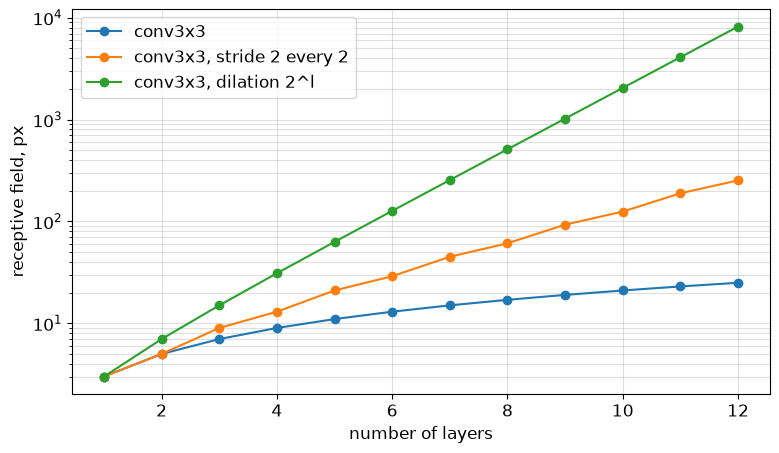

In [69]:
depths = range(1, 13)
designs = {
    'conv3x3':                   lambda L: [dict(k=3)] * L,
    'conv3x3, stride 2 every 2': lambda L: [dict(k=3, s=2 if l % 2 == 1 else 1) for l in range(L)],
    'conv3x3, dilation 2^l':     lambda L: [dict(k=3, d=2 ** l) for l in range(L)],
}
plt.figure(figsize=(9, 5))
for label, make in designs.items():
    plt.plot(depths, [receptive_field(make(L))[-1][0] for L in depths], 'o-', label=label)
plt.yscale('log')
plt.xlabel('number of layers')
plt.ylabel('receptive field, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

---
# 9. Функции активации

| | формула | производная |
|---|---|---|
| sigmoid | $\sigma(x) = \frac{1}{1 + e^{-x}}$ | $\sigma(x)(1 - \sigma(x)) \le \frac14$ |
| tanh | $\tanh x$ | $1 - \tanh^2 x \le 1$ |
| ReLU | $\max(0, x)$ | $\mathbf{1}[x > 0]$ |
| GELU | $x\,\Phi(x)$, $\Phi$ — CDF $\mathcal N(0,1)$ | гладкая |
| SiLU (Swish) | $x\,\sigma(x)$ | гладкая |

Без нелинейности стопка свёрток — это одна свёртка. Но активация определяет ещё и то, как через сеть проходят градиенты.

In [70]:
activations = {
    'sigmoid': torch.sigmoid,
    'tanh': torch.tanh,
    'ReLU': F.relu,
    'GELU': F.gelu,
    'SiLU': F.silu,
}

In [71]:
z = torch.linspace(-6, 6, 1001, requires_grad=True)
values, derivatives = {}, {}
for name, act in activations.items():
    y = act(z)
    derivatives[name], = torch.autograd.grad(y.sum(), z)   # поэлементно: y_i зависит только от z_i
    values[name] = y.detach()

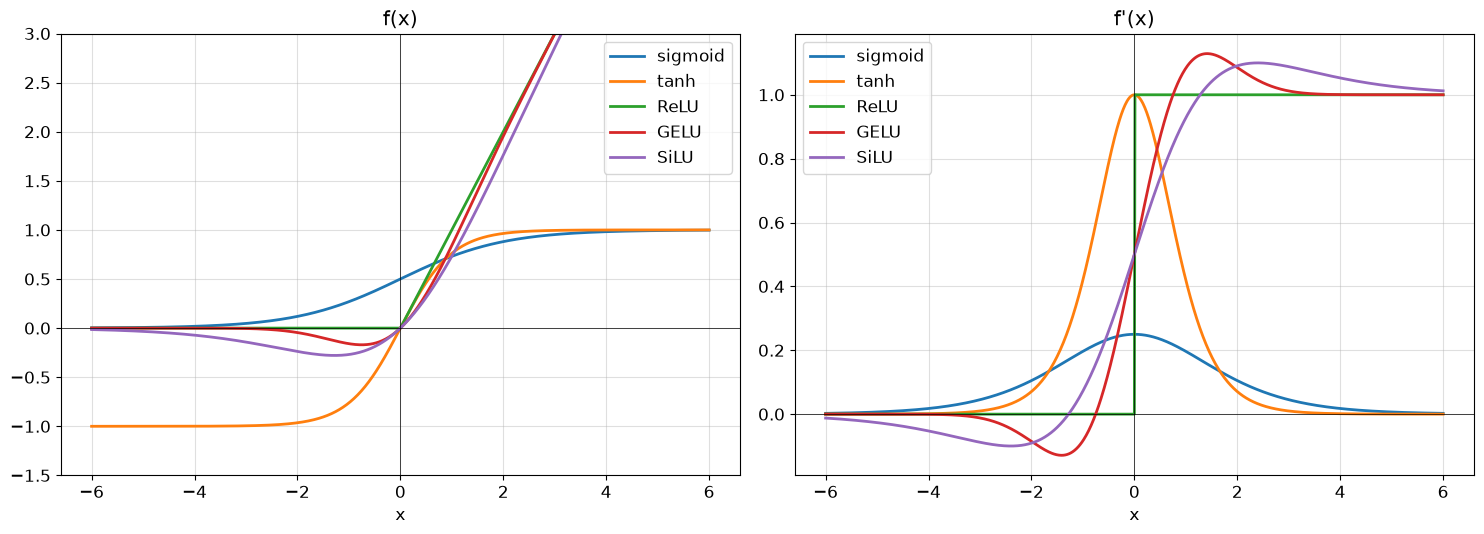

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
for name in activations:
    ax1.plot(z.detach(), values[name], label=name, linewidth=2)
    ax2.plot(z.detach(), derivatives[name], label=name, linewidth=2)
ax1.set_ylim(-1.5, 3)
for ax, title in [(ax1, 'f(x)'), (ax2, "f'(x)")]:
    ax.set_title(title)
    ax.set_xlabel('x')
    ax.axhline(0, color='k', linewidth=0.5)
    ax.axvline(0, color='k', linewidth=0.5)
    ax.grid(True, alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

## 9.1 Saturation

$$\sigma'(x) = \sigma(x)\big(1 - \sigma(x)\big) \le \tfrac14, \qquad \prod_{l=1}^{L} \sigma'(x_l) \le 4^{-L}$$

При больших $|x|$ sigmoid и tanh выходят на плато, производная почти нулевая: нейрон **насыщен**.

In [74]:
x = torch.tensor([0., 2., 5., 10.], requires_grad=True)
for name in ['sigmoid', 'tanh']:
    dy_dx, = torch.autograd.grad(activations[name](x).sum(), x)
    print(f"{name:<8} f'({x.tolist()}) = {[f'{v:.1e}' for v in dy_dx.tolist()]}")

sigmoid  f'([0.0, 2.0, 5.0, 10.0]) = ['2.5e-01', '1.0e-01', '6.6e-03', '4.5e-05']
tanh     f'([0.0, 2.0, 5.0, 10.0]) = ['1.0e+00', '7.1e-02', '1.8e-04', '0.0e+00']


In [75]:
0.25 ** 10

9.5367431640625e-07

## 9.2 Dead ReLU

$$x < 0: \quad \mathrm{ReLU}(x) = 0, \quad \mathrm{ReLU}'(x) = 0$$

Если нейрон в отрицательной области **на всех объектах**, градиент по его весам нулевой, и нейрон больше никогда не обновится.

In [76]:
x = torch.tensor([-2., -0.5, 0.5, 2.], requires_grad=True)
torch.autograd.grad(F.relu(x).sum(), x)[0]

tensor([0., 0., 1., 1.])

In [77]:
torch.manual_seed(0)
neuron = nn.Linear(10, 1)
with torch.no_grad():
    neuron.bias.fill_(-10.0)

pre = neuron(torch.randn(512, 10))
F.relu(pre).sum().backward()
print('active fraction:', (pre > 0).float().mean().item())
print('grad weight:', neuron.weight.grad.abs().max().item(), '| grad bias:', neuron.bias.grad.item())

active fraction: 0.0
grad weight: 0.0 | grad bias: 0.0


## 9.3 Gradient flow в глубокой сети

MLP: 15 слоёв, ширина 128, $W \sim \mathcal N(0,\, 2/\text{fan\_in})$, $b = 0$, одна и та же инициализация для всех активаций.

$$L = \langle h_{\text{out}}, r \rangle, \quad r \sim \mathcal N(0, I) \text{ фиксирован}$$

In [78]:
def make_mlp_layers(depth=15, width=128, weight_scale=1.0, seed=0):
    torch.manual_seed(seed)
    layers = [nn.Linear(width, width) for _ in range(depth)]
    for layer in layers:
        nn.init.normal_(layer.weight, std=weight_scale * math.sqrt(2 / width))
        nn.init.zeros_(layer.bias)
    return layers

In [79]:
def small_derivative_fraction(act, pre, threshold=1e-2):
    # доля нейронов с |f'(pre)| < threshold: насыщенные или мёртвые
    pre = pre.detach().requires_grad_(True)
    d_act, = torch.autograd.grad(act(pre).sum(), pre)
    return (d_act.abs() < threshold).float().mean().item()


def layer_grad_norms(act, weight_scale=1.0):
    layers = make_mlp_layers(weight_scale=weight_scale)
    h = torch.randn(512, 128)
    fractions = []
    for layer in layers:
        pre = layer(h)
        fractions.append(small_derivative_fraction(act, pre))
        h = act(pre)
    probe = torch.randn_like(h) / h.shape[0]
    (h * probe).sum().backward()
    return [layer.weight.grad.norm().item() for layer in layers], float(np.mean(fractions))

In [80]:
experiments = {name: dict(act=act) for name, act in activations.items()}
experiments['tanh, W x3'] = dict(act=torch.tanh, weight_scale=3.0)

grad_norms = {}
print(f'{"activation":<12}{"|grad W_1|":>12}{"|grad W_15|":>13}{"first/last":>12}{"small f`":>10}')
for name, kwargs in experiments.items():
    grad_norms[name], small = layer_grad_norms(**kwargs)
    g = grad_norms[name]
    print(f'{name:<12}{g[0]:>12.1e}{g[-1]:>13.1e}{g[0] / g[-1]:>12.1e}{small:>10.2f}')

activation    |grad W_1|  |grad W_15|  first/last  small f`
sigmoid          1.2e-07      6.7e-01     1.8e-07      0.00
tanh             5.8e+00      2.4e+00     2.4e+00      0.00
ReLU             2.8e+00      2.3e+00     1.2e+00      0.52
GELU             5.6e-01      2.3e-01     2.5e+00      0.01
SiLU             6.9e-02      4.4e-02     1.6e+00      0.01
tanh, W x3       1.2e+03      1.8e+00     6.5e+02      0.43


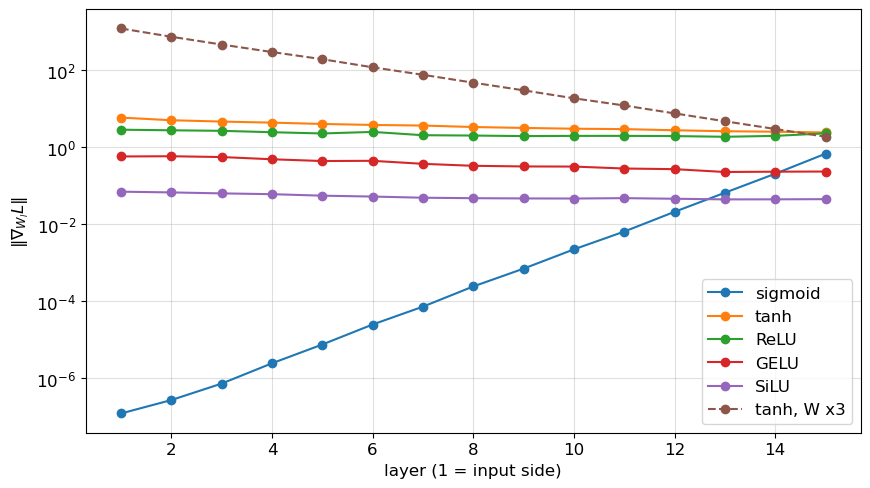

In [60]:
plt.figure(figsize=(10, 5.5))
for name, norms in grad_norms.items():
    plt.plot(range(1, len(norms) + 1), norms, marker='o', label=name,
             linestyle='--' if 'x3' in name else '-')
plt.yscale('log')
plt.xlabel('layer (1 = input side)')
plt.ylabel(r'$\|\nabla_{W_l} L\|$')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

- **sigmoid**: градиент затухает на несколько порядков от последнего слоя к первому, потому что $\sigma' \le 1/4$ на каждом слое;
- **ReLU**: около половины нейронов на каждом объекте в нуле, но норма градиента по слоям стабильна;
- **tanh с весами ×3**: заметная доля насыщенных нейронов, но градиент к первым слоям **растёт**: маленькие $f'$ перевешиваются большими $W$. Насыщение само по себе ещё не vanishing.

Активация и инициализация вместе определяют, дойдёт ли градиент до первых слоёв.

## 9.4\* Gated activations: GLU, SwiGLU, GEGLU

В современных трансформерах (LLM, DiT, Stable Diffusion) нелинейность стоит в feed-forward блоке, и почти всегда она **gated**: одна проекция проходит через активацию и поэлементно умножается на другую.

| | формула | где |
|---|---|---|
| FFN | $W_2\, \mathrm{act}(W_1 x)$ | BERT, GPT-2 (GELU) |
| GLU | $(W x) \odot \sigma(V x)$ | Dauphin et al., 2017 |
| ReGLU | $\mathrm{ReLU}(W x) \odot V x$ | Shazeer, 2020 |
| GEGLU | $\mathrm{GELU}(W x) \odot V x$ | T5 v1.1, FFN в Stable Diffusion |
| SwiGLU | $\mathrm{SiLU}(W x) \odot V x$ | PaLM, LLaMA, Mistral |
| ReLU² | $\mathrm{ReLU}(x)^2$ | Primer |

$$
\mathrm{FFN}_{\mathrm{SwiGLU}}(x) = W_{\text{down}}\big(\mathrm{SiLU}(W_{\text{gate}}\, x) \odot W_{\text{up}}\, x\big)
$$

In [61]:
t = torch.randn(4, 10)
a, b = t.chunk(2, dim=-1)
torch.allclose(F.glu(t, dim=-1), a * torch.sigmoid(b))   # в PyTorch GLU — готовая функция

True

In [62]:
class FFN(nn.Module):
    def __init__(self, d, hidden, act=F.gelu):
        super().__init__()
        self.up = nn.Linear(d, hidden, bias=False)
        self.down = nn.Linear(hidden, d, bias=False)
        self.act = act

    def forward(self, x):
        return self.down(self.act(self.up(x)))


class GatedFFN(nn.Module):
    def __init__(self, d, hidden, act=F.silu):
        super().__init__()
        self.gate = nn.Linear(d, hidden, bias=False)
        self.up = nn.Linear(d, hidden, bias=False)
        self.down = nn.Linear(hidden, d, bias=False)
        self.act = act

    def forward(self, x):
        return self.down(self.act(self.gate(x)) * self.up(x))   # SiLU -> SwiGLU, GELU -> GEGLU

У gated FFN три матрицы вместо двух. Чтобы число параметров совпадало, hidden берут $\frac23 \cdot 4d = \frac83 d$ (так в LLaMA).

In [63]:
d = 512
ffn = FFN(d, 4 * d)
swiglu = GatedFFN(d, int(8 * d / 3), act=F.silu)
geglu = GatedFFN(d, int(8 * d / 3), act=F.gelu)

x = torch.randn(2, 16, d)   # (batch, tokens, d)
for name, m in [('FFN (GELU)', ffn), ('SwiGLU', swiglu), ('GEGLU', geglu)]:
    print(f'{name:<11} params: {sum(p.numel() for p in m.parameters()):>9,}   out: {tuple(m(x).shape)}')

FFN (GELU)  params: 2,097,152   out: (2, 16, 512)
SwiGLU      params: 2,096,640   out: (2, 16, 512)
GEGLU       params: 2,096,640   out: (2, 16, 512)


Один нейрон gated FFN — функция двух входов $h(a, b) = \mathrm{act}(a) \cdot b$, где $a = w_{\text{gate}}^\top x$, $b = w_{\text{up}}^\top x$. Вход $b$ управляет и знаком, и масштабом выхода — это мультипликативное взаимодействие, которого у обычной активации нет.

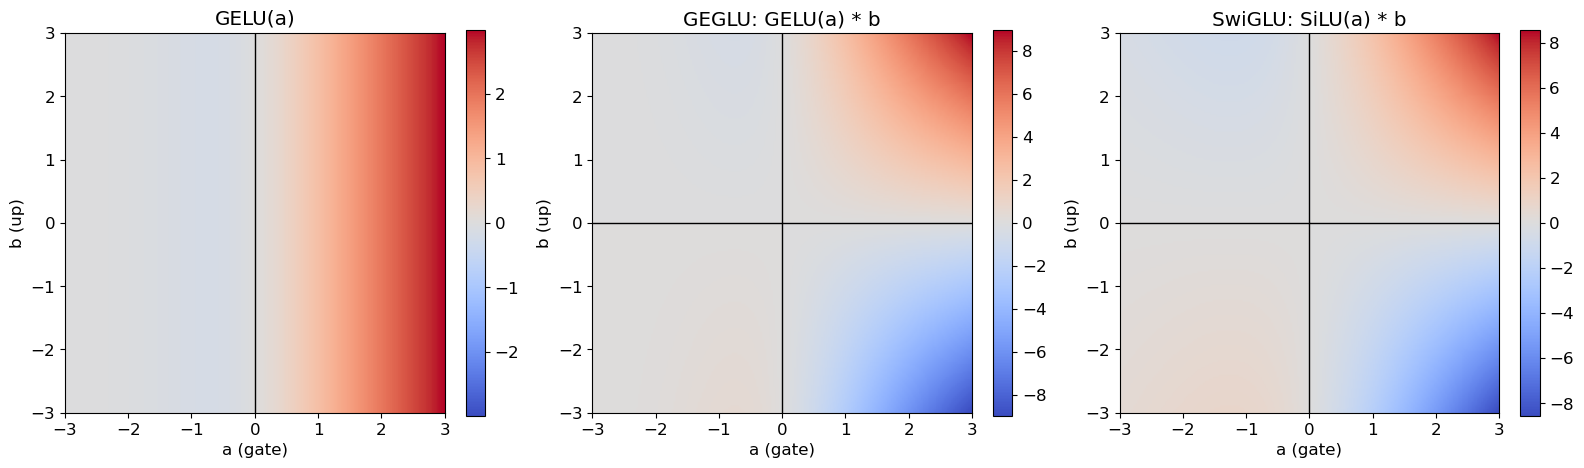

In [64]:
grid = torch.linspace(-3, 3, 201)
A, B = torch.meshgrid(grid, grid, indexing='xy')
units = {
    'GELU(a)': F.gelu(A),
    'GEGLU: GELU(a) * b': F.gelu(A) * B,
    'SwiGLU: SiLU(a) * b': F.silu(A) * B,
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, H) in zip(axes, units.items()):
    vmax = H.abs().max()
    im = ax.imshow(H, extent=(-3, 3, -3, 3), origin='lower', cmap='coolwarm', vmin=-vmax, vmax=vmax)
    ax.contour(A, B, H, levels=[0], colors='k', linewidths=1)
    ax.set_title(name)
    ax.set_xlabel('a (gate)')
    ax.set_ylabel('b (up)')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### GELU: точная формула и tanh-приближение

$$\mathrm{GELU}(x) = x\,\Phi(x) \approx \tfrac12 x\Big(1 + \tanh\big(\sqrt{2/\pi}\,(x + 0.044715\,x^3)\big)\Big)$$

Приближение используют GPT-2 и DiT; в PyTorch — `F.gelu(x, approximate='tanh')`.

In [65]:
z = torch.linspace(-6, 6, 10001)
exact, approx = F.gelu(z), F.gelu(z, approximate='tanh')
manual = 0.5 * z * (1 + torch.tanh(math.sqrt(2 / math.pi) * (z + 0.044715 * z ** 3)))
assert torch.allclose(approx, manual, atol=1e-6)
(exact - approx).abs().max().item()

0.0004734992980957031

### 9.5\* GELU руками vs `F.gelu`: память и время backward

Формула из примитивов (`mul`, `pow`, `add`, `tanh`) — это цепочка отдельных операций. Autograd сохраняет для backward **промежуточный тензор каждой**. `F.gelu` — одна операция: сохраняет только вход и пересчитывает всё нужное в своём backward.

In [66]:
def gelu_manual(x):
    return 0.5 * x * (1 + torch.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x ** 3)))


def saved_for_backward_mb(fn, x):
    total = 0

    def pack(t):
        nonlocal total
        total += t.numel() * t.element_size()
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        fn(x)
    return total / 2 ** 20

In [67]:
x = torch.randn(2048, 2048, requires_grad=True)
gelu_variants = {'manual': gelu_manual,
                 "F.gelu(approximate='tanh')": lambda t: F.gelu(t, approximate='tanh'),
                 'F.gelu': F.gelu}

print(f'input: {x.numel() * x.element_size() / 2 ** 20:.0f} MB')
for name, fn in gelu_variants.items():
    t = min(timeit.repeat(lambda: fn(x).sum().backward(), number=3, repeat=3)) / 3
    print(f'{name:<28} saved: {saved_for_backward_mb(fn, x):>4.0f} MB   fwd+bwd: {t * 1000:5.1f} ms')

input: 16 MB


manual                       saved:   64 MB   fwd+bwd:  37.8 ms
F.gelu(approximate='tanh')   saved:   16 MB   fwd+bwd:  18.6 ms


F.gelu                       saved:   16 MB   fwd+bwd:  11.8 ms


In [68]:
from torch.profiler import profile, ProfilerActivity

for name in ['manual', "F.gelu(approximate='tanh')"]:
    with profile(activities=[ProfilerActivity.CPU]) as prof:
        gelu_variants[name](x).sum().backward()
    # aten::* — низкоуровневые операторы PyTorch (C++), по одному ядру на вызов
    ops = [e for e in prof.key_averages() if e.key.startswith('aten::')]
    print(f'{name}: {sum(e.count for e in ops)} aten calls')
    print(prof.key_averages().table(sort_by='self_cpu_time_total', row_limit=5, max_name_column_width=30))

manual: 71 aten calls
------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                          Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                     aten::mul        40.54%      13.071ms        40.89%      13.182ms       1.198ms            11  
                    aten::tanh        22.12%       7.133ms        22.12%       7.133ms       7.133ms             1  
                     aten::add         8.70%       2.806ms         8.76%       2.824ms       1.412ms             2  
                     aten::pow         8.06%       2.597ms         8.07%       2.601ms       1.300ms             2  
                    aten::add_         7.65%       2.467ms         7.65%       2.467ms     822.493us             3  
------------------------------  ----------

Вывод: активации и нормализации (`F.gelu`, `F.silu`, `F.layer_norm`, `F.scaled_dot_product_attention`) не пишут руками из примитивов — берут готовые fused операции или `torch.compile`, который сливает цепочку в одно ядро.

---
# Семинар 4. Оптимизаторы, residual connections, adversarial examples

# 10. Динамика оптимизаторов

Плохо обусловленная квадратичная функция:
$$
f(x, y) = \frac12\left(a x^2 + b y^2\right), \qquad a = 1,\; b = 20, \qquad \kappa = b/a = 20.
$$

Кривизна по $y$ в 20 раз больше, чем по $x$. Так часто выглядит loss нейросети локально: по одним направлениям очень крутой, по другим — пологий.

In [81]:
A_COEF, B_COEF = 1.0, 20.0
START = (-4.5, 2.0)


def quadratic(p):
    return 0.5 * (A_COEF * p[0] ** 2 + B_COEF * p[1] ** 2)

In [82]:
def run_optimizer(f, make_optimizer, start=START, steps=100):
    p = torch.tensor([start], requires_grad=True)   # точка как матрица 1x2: нужно для Muon и Shampoo
    optimizer = make_optimizer([p])
    trajectory = [p.detach().view(-1).clone()]
    for _ in range(steps):
        optimizer.zero_grad()
        f(p.view(-1)).backward()
        optimizer.step()
        trajectory.append(p.detach().view(-1).clone())
    return torch.stack(trajectory)   # (steps + 1, 2)

In [83]:
QUAD_VIEW = dict(xlim=(-5, 5), ylim=(-2.6, 2.6), levels=np.logspace(-2, 2, 15), minimum=(0, 0))
OPT_COLORS = {'SGD': '#D55E00', 'Momentum': '#0072B2', 'Adam': '#009E73',
              'Lion': '#E69F00', 'Muon': '#CC79A7', 'Shampoo': '#56B4E9'}


def color_of(name):
    return OPT_COLORS[name.split(',')[0]]


def plot_contour(ax, f, xlim, ylim, levels, minimum):
    X, Y = torch.meshgrid(torch.linspace(*xlim, 300), torch.linspace(*ylim, 300), indexing='xy')
    ax.contour(X, Y, f(torch.stack([X, Y])), levels=levels, cmap='Greys', linewidths=0.8)
    ax.plot(*minimum, 'kx', markersize=12, mew=3)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

In [84]:
def plot_trajectories(f, trajectories, title, colors=None, **view):
    colors = colors or [color_of(name) for name in trajectories]
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_contour(ax, f, **view)
    for (name, traj), color in zip(trajectories.items(), colors):
        ax.plot(traj[:, 0], traj[:, 1], 'o-', color=color, markersize=3, linewidth=1.5, label=name)
    ax.plot(*traj[0], 'k*', markersize=15)
    ax.set_title(title)
    ax.legend(loc='lower right', fontsize=10)
    plt.show()

## 10.1 SGD

$$\theta_{t+1} = \theta_t - \eta\, g_t$$

На квадратичной функции координаты независимы:
$$x_{t+1} = (1 - \eta a)\, x_t, \qquad y_{t+1} = (1 - \eta b)\, y_t.$$

Сходимость $\iff |1 - \eta b| < 1 \iff \eta < 2/b = 0.1$. При $\eta = 0.09$ множитель по $y$ равен $-0.8$ (скачки через ось), по $x$ — $0.91$ (медленное движение вдоль оврага).

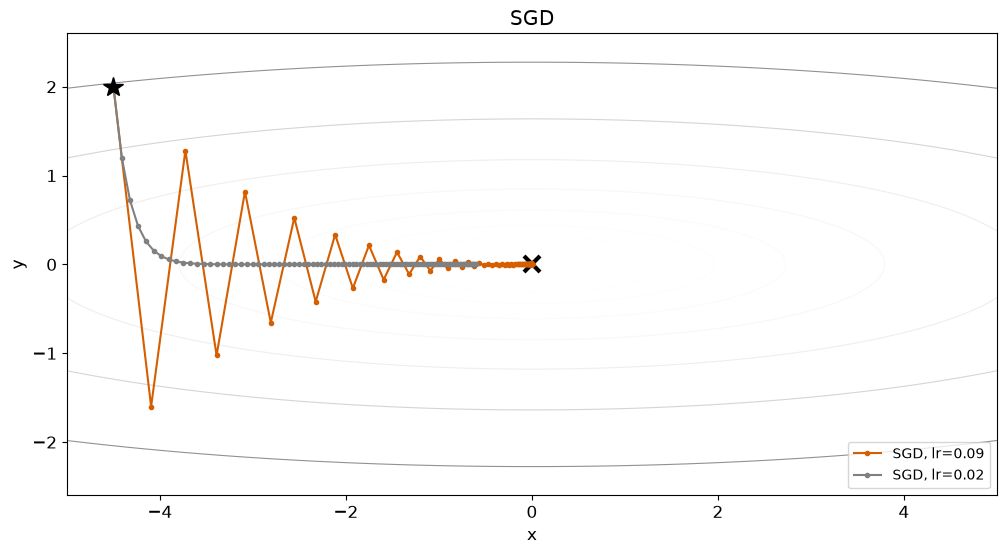

In [85]:
sgd_runs = {f'SGD, lr={lr}': run_optimizer(quadratic, lambda ps, lr=lr: torch.optim.SGD(ps, lr=lr))
            for lr in [0.09, 0.02]}
plot_trajectories(quadratic, sgd_runs, 'SGD', colors=[OPT_COLORS['SGD'], 'gray'], **QUAD_VIEW)

In [88]:
# граница устойчивости eta = 2 / b = 0.1
for lr in [0.09, 0.099, 0.101, 0.11]:
    traj = run_optimizer(quadratic, lambda ps: torch.optim.SGD(ps, lr=lr))
    print(f'lr = {lr:<6} |y_100| = {traj[-1, 1].abs().item():.2e}')

lr = 0.09   |y_100| = 4.07e-10
lr = 0.099  |y_100| = 2.65e-01
lr = 0.101  |y_100| = 1.45e+01
lr = 0.11   |y_100| = 1.66e+08


## 10.2 Momentum

$$v_{t+1} = \mu v_t + g_t, \qquad \theta_{t+1} = \theta_t - \eta\, v_{t+1}$$

$v$ — экспоненциально взвешенная сумма градиентов. По $y$ знаки градиента чередуются и гасят друг друга, по $x$ градиент всё время одного знака и накапливается.

In [94]:
mom_traj = run_optimizer(quadratic, lambda ps: torch.optim.SGD(ps, lr=0.02, momentum=0.8))

# torch.optim.SGD(momentum) — ровно формула выше
p_manual, v = torch.tensor(START), torch.zeros(2)
for _ in range(100):
    v = 0.8 * v + torch.tensor([A_COEF, B_COEF]) * p_manual
    p_manual = p_manual - 0.02 * v
assert torch.allclose(p_manual, mom_traj[-1], atol=1e-6)

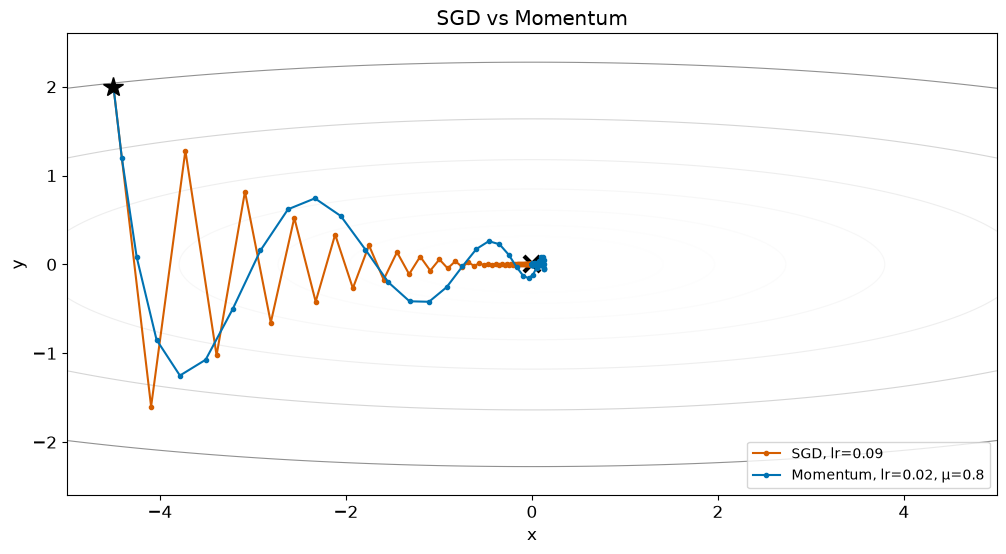

In [95]:
plot_trajectories(quadratic, {'SGD, lr=0.09': sgd_runs['SGD, lr=0.09'],
                              'Momentum, lr=0.02, μ=0.8': mom_traj}, 'SGD vs Momentum', **QUAD_VIEW)

## 10.3 Adam

Покоординатные оценки первого и второго моментов градиента:
$$
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta_{t+1} = \theta_t - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$

Деление на $\sqrt{\hat v_t}$ нормирует шаг **по каждой координате**.

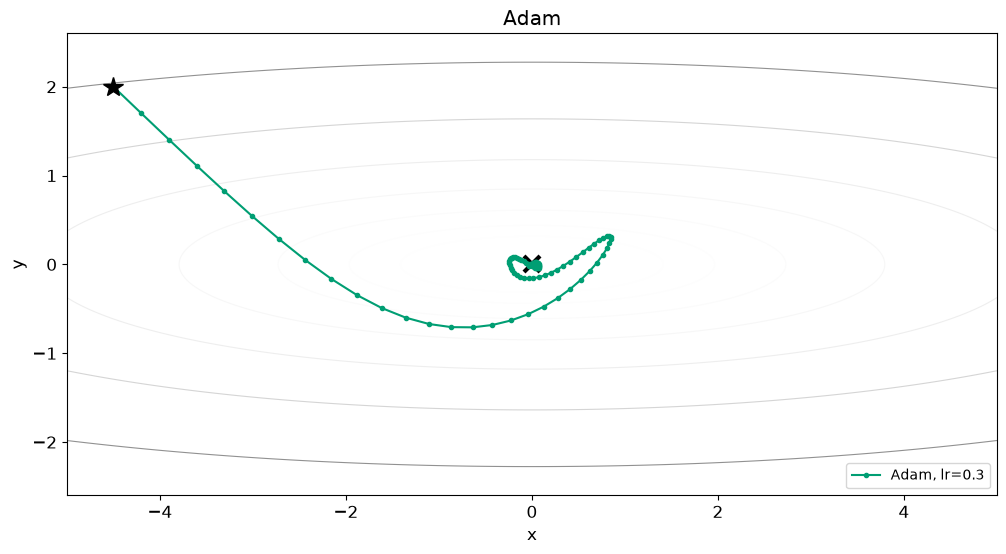

In [98]:
adam_traj = run_optimizer(quadratic, lambda ps: torch.optim.Adam(ps, lr=0.3))
plot_trajectories(quadratic, {'Adam, lr=0.3': adam_traj}, 'Adam', **QUAD_VIEW)

Adam в начале идёт почти по диагонали: шаг по каждой координате $\approx \eta$, масштаб кривизны по осям почти не важен. Около минимума он начинает осциллировать.

## 10.4 Анимация сходимости

In [99]:
def animate_trajectories(f, trajectories, path, every=1, fps=15, hold=2, legend_loc='lower right', **view):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.5, 1]})
    plot_contour(ax1, f, **view)
    losses = {name: [max(f(p).item(), 1e-12) for p in traj] for name, traj in trajectories.items()}
    n_steps = len(next(iter(losses.values())))
    artists = []
    for name in trajectories:
        artists.append((ax1.plot([], [], '-', color=color_of(name), linewidth=1.5, label=name)[0],
                        ax1.plot([], [], 'o', color=color_of(name), markersize=8)[0],
                        ax2.plot([], [], color=color_of(name), linewidth=2)[0]))
    ax1.legend(loc=legend_loc, fontsize=9)
    ax2.set(xlim=(0, n_steps), yscale='log', xlabel='step', ylabel='f(x, y)')
    ax2.set_ylim(min(min(l) for l in losses.values()) / 2, 2 * max(max(l) for l in losses.values()))
    ax2.grid(True, which='both', alpha=0.4)

    def update(t):
        for (line, point, curve), (name, traj) in zip(artists, trajectories.items()):
            line.set_data(traj[:t + 1, 0], traj[:t + 1, 1])
            point.set_data([traj[t, 0]], [traj[t, 1]])
            curve.set_data(range(t + 1), losses[name][:t + 1])
        ax1.set_title(f'step {t}')

    frames = list(range(0, n_steps, every)) + [n_steps - 1] * (hold * fps)   # пауза на последнем кадре
    FuncAnimation(fig, update, frames=frames).save(path, writer=PillowWriter(fps=fps), dpi=70)
    plt.close(fig)
    return Image(filename=path)   # интерактивный плеер: HTML(anim.to_jshtml()), но notebook станет тяжелее

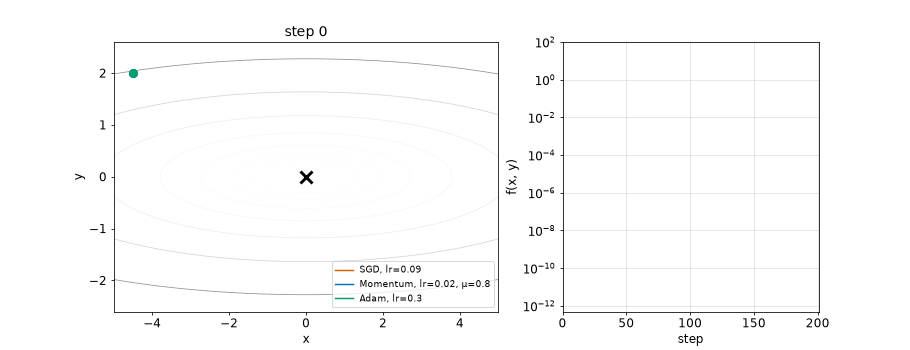

In [100]:
classic_makers = {
    'SGD, lr=0.09':             lambda ps: torch.optim.SGD(ps, lr=0.09),
    'Momentum, lr=0.02, μ=0.8': lambda ps: torch.optim.SGD(ps, lr=0.02, momentum=0.8),
    'Adam, lr=0.3':             lambda ps: torch.optim.Adam(ps, lr=0.3),
}
quad_runs = {name: run_optimizer(quadratic, make, steps=200) for name, make in classic_makers.items()}
animate_trajectories(quadratic, quad_runs, 'optimizers_quadratic.gif', every=2, **QUAD_VIEW)

> Этот эксперимент показывает разницу динамики, но не является честным рейтингом optimizer'ов: результат зависит от learning rate, schedule, архитектуры и задачи.

## 10.5 Adam vs AdamW

`Adam(weight_decay=λ)` — L2 в градиенте, проходит через адаптивную нормировку:
$$g_t \leftarrow \nabla L(\theta_t) + \lambda \theta_t, \qquad \theta_{t+1} = \theta_t - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

У параметров с большими градиентами регуляризация фактически ослабляется. `AdamW` — decoupled weight decay:
$$\theta_{t+1} = \theta_t - \eta \lambda \theta_t - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

Проверка: $\nabla L = 0$, работает только weight decay.

In [101]:
for opt_cls in [torch.optim.Adam, torch.optim.AdamW]:
    for wd in [1e-4, 1e-2]:
        p = torch.tensor([1.0, 10.0], requires_grad=True)
        opt = opt_cls([p], lr=0.1, weight_decay=wd)
        (0 * p).sum().backward()
        opt.step()
        print(f'{opt_cls.__name__:<6} wd={wd:<7} [1, 10] -> {[round(v, 5) for v in p.tolist()]}')

Adam   wd=0.0001  [1, 10] -> [0.90001, 9.9]
Adam   wd=0.01    [1, 10] -> [0.9, 9.9]
AdamW  wd=0.0001  [1, 10] -> [0.99999, 9.9999]
AdamW  wd=0.01    [1, 10] -> [0.999, 9.99]


## 10.6 Современные оптимизаторы: Lion, \*Muon, \*Shampoo

| | обновление | состояние на параметр $W \in \mathbb R^{m \times n}$ |
|---|---|---|
| SGD + Momentum | $W \leftarrow W - \eta\, M$ | $M$: $mn$ |
| Adam | покоординатно $\hat m / \sqrt{\hat v}$ | $m, v$: $2mn$ |
| Lion (Chen et al., 2023) | $\mathrm{sign}(\cdot)$ от смеси momentum и градиента | $M$: $mn$ |
| Muon (Jordan et al., 2024) | ортогонализованный momentum $U V^\top$ | $M$: $mn$ |
| Shampoo (Gupta et al., 2018) | $L^{-1/4}\, G\, R^{-1/4}$ | $L$: $m^2$, $R$: $n^2$ |

Adam — **диагональный** предобуславливатель: каждая координата нормируется отдельно. Muon и Shampoo используют то, что параметр — **матрица**.

### Lion

$$
c_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
\theta_{t+1} = \theta_t - \eta\, \mathrm{sign}(c_t), \qquad
m_t = \beta_2 m_{t-1} + (1 - \beta_2) g_t
$$

Каждая координата сдвигается ровно на $\pm\eta$; состояние одно — вдвое меньше памяти, чем у Adam.

In [102]:
class Lion(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99)):
        super().__init__(params, dict(lr=lr, betas=betas))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                m = self.state[p].setdefault('m', torch.zeros_like(p))
                p.add_(torch.sign(beta1 * m + (1 - beta1) * p.grad), alpha=-group['lr'])
                m.mul_(beta2).add_(p.grad, alpha=1 - beta2)

### \*Muon

Для матричного параметра $W$ с momentum $M_t$ и SVD $M_t = U \Sigma V^\top$:
$$W \leftarrow W - \eta\, U V^\top.$$

Все сингулярные числа шага приводятся к $\approx 1$: шаг одинаково «сильный» по всем направлениям. SVD дорогая, поэтому $U V^\top$ приближают 5 итерациями Newton–Schulz:
$$X_0 = \frac{M}{\|M\|_F}, \qquad X_{k+1} = a X_k + b\, (X_k X_k^\top) X_k + c\, (X_k X_k^\top)^2 X_k,$$
$(a, b, c) = (3.4445,\, -4.7750,\, 2.0315)$. В PyTorch — `torch.optim.Muon` (только для 2D параметров; embeddings, головы и bias обычно оставляют AdamW).

In [82]:
def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
    a, b, c = coeffs
    X = M / (M.norm() + 1e-7)
    transposed = X.shape[0] > X.shape[1]
    if transposed:
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if transposed else X


torch.manual_seed(0)
M = torch.randn(64, 32) * torch.logspace(0, -3, 32)   # плохо обусловленная матрица
s_before, s_after = torch.linalg.svdvals(M), torch.linalg.svdvals(newton_schulz(M))
print(f'singular values of M:     {s_before.max():.2e} .. {s_before.min():.2e}, ratio {s_before.max() / s_before.min():.0f}')
print(f'singular values of NS(M): {s_after.max():.2f} .. {s_after.min():.2f}, ratio {s_after.max() / s_after.min():.1f}')

singular values of M:     8.48e+00 .. 5.52e-03, ratio 1536
singular values of NS(M): 1.20 .. 0.20, ratio 6.1


Наша точка на плоскости — матрица $1 \times 2$. У неё одно сингулярное число, и $U V^\top = g / \|g\|$: в 2D Muon превращается в **нормированный** momentum-шаг постоянной длины.

In [83]:
p = torch.tensor([START], requires_grad=True)
opt = torch.optim.Muon([p], lr=0.1, weight_decay=0)
quadratic(p.view(-1)).backward()
g = p.grad.view(-1).clone()
opt.step()
step = p.detach().view(-1) - torch.tensor(START)
print('cos(step, -g) =', F.cosine_similarity(step, -g, dim=0).item())
print('|step| =', step.norm().item())

cos(step, -g) = 0.9999998807907104
|step| = 0.06918701529502869


### \*Shampoo

Для матричного градиента $G_t \in \mathbb R^{m \times n}$ копим два предобуславливателя — по строкам и по столбцам:
$$L_t = \beta_2 L_{t-1} + (1 - \beta_2)\, G_t G_t^\top, \qquad R_t = \beta_2 R_{t-1} + (1 - \beta_2)\, G_t^\top G_t,$$
$$W \leftarrow W - \eta\, L_t^{-1/4}\, M_t\, R_t^{-1/4}.$$

В отличие от Adam предобуславливатель **не диагональный**: он учитывает корреляции между координатами. Здесь упрощённый вариант с EMA и momentum $M_t$; в реальных реализациях (Distributed Shampoo, SOAP) добавляют grafting, редкий пересчёт корней и т.п.

In [104]:
def inverse_root(A, k, eps=1e-12):
    # A^{-1/k} для симметричной A через собственное разложение
    eigvals, V = torch.linalg.eigh(A)
    return V @ torch.diag(eigvals.clamp_min(eps) ** (-1 / k)) @ V.T


class Shampoo(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, betas=(0.9, 0.99), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                G, state = p.grad, self.state[p]   # G: (m, n)
                if not state:
                    state['L'] = group['eps'] * torch.eye(G.shape[0])
                    state['R'] = group['eps'] * torch.eye(G.shape[1])
                    state['M'] = torch.zeros_like(G)
                state['L'].mul_(beta2).add_(G @ G.T, alpha=1 - beta2)
                state['R'].mul_(beta2).add_(G.T @ G, alpha=1 - beta2)
                state['M'].mul_(beta1).add_(G, alpha=1 - beta1)
                p.add_(inverse_root(state['L'], 4) @ state['M'] @ inverse_root(state['R'], 4), alpha=-group['lr'])

## 10.7 Все оптимизаторы на функции Розенброка

$$f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2, \qquad \min f = f(1, 1) = 0$$

Узкая изогнутая «банановая» долина: дно пологое, стенки крутые, и направление долины всё время меняется. Learning rate у всех постоянный.

In [105]:
def rosenbrock(p):
    return (1 - p[0]) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2


ROSEN_START = (-1.5, 2.0)
ROSEN_VIEW = dict(xlim=(-2, 2), ylim=(-1, 3), levels=np.logspace(-1, 3.5, 20), minimum=(1, 1))
all_makers = {
    'SGD, lr=1e-3':             lambda ps: torch.optim.SGD(ps, lr=1e-3),
    'Momentum, lr=1e-3, μ=0.9': lambda ps: torch.optim.SGD(ps, lr=1e-3, momentum=0.9),
    'Adam, lr=0.05':            lambda ps: torch.optim.Adam(ps, lr=0.05),
    'Lion, lr=0.01':            lambda ps: Lion(ps, lr=0.01),
    'Muon, lr=0.01':            lambda ps: torch.optim.Muon(ps, lr=0.01, weight_decay=0),
    'Shampoo, lr=0.1':          lambda ps: Shampoo(ps, lr=0.1),
}
rosen_runs = {name: run_optimizer(rosenbrock, make, ROSEN_START, steps=1500) for name, make in all_makers.items()}

In [106]:
def first_step_below(values, threshold):
    below = (values < threshold).nonzero()
    return below[0].item() if len(below) else '-'


print(f'{"optimizer":<26}{"f(final)":>10}{"min f":>10}{"f<1e-2 at":>12}{"f<1e-4 at":>12}')
for name, traj in rosen_runs.items():
    values = torch.stack([rosenbrock(p) for p in traj])
    print(f'{name:<26}{values[-1]:>10.1e}{values.min():>10.1e}'
          f'{first_step_below(values, 1e-2):>12}{first_step_below(values, 1e-4):>12}')

optimizer                   f(final)     min f   f<1e-2 at   f<1e-4 at
SGD, lr=1e-3                 6.4e-01   6.4e-01           -           -
Momentum, lr=1e-3, μ=0.9     8.7e-07   8.7e-07         416         934
Adam, lr=0.05                1.3e-07   1.3e-07         717        1090
Lion, lr=0.01                3.1e-02   2.1e-09         355         372
Muon, lr=0.01                3.2e-03   7.0e-05         593         907
Shampoo, lr=0.1              3.5e-05   2.6e-07         350         522


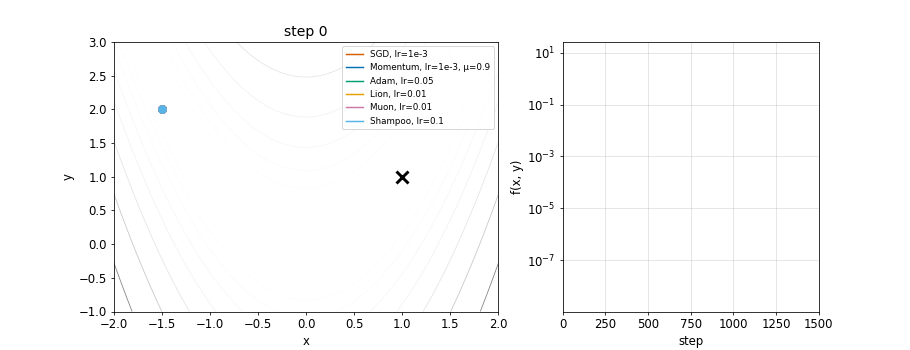

In [87]:
animate_trajectories(rosenbrock, rosen_runs, 'optimizers_rosenbrock.gif', every=10, legend_loc='upper right', **ROSEN_VIEW)

SGD за 1500 шагов так и не проходит долину: learning rate ограничен крутыми стенками, а по дну шаги крошечные. У Lion, Muon и Shampoo длина шага почти не зависит от масштаба градиента (у Lion — ровно $\pm\eta$ по координате, у Muon — $\approx\eta$ по норме). Поэтому с постоянным learning rate они доходят до минимума и начинают вокруг него «дрожать»: `min f` на порядки меньше `f(final)`. Лечится schedule:

In [107]:
for use_schedule in [False, True]:
    p = torch.tensor([ROSEN_START], requires_grad=True)
    opt = Lion([p], lr=0.01)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=1500) if use_schedule else None
    for _ in range(1500):
        opt.zero_grad()
        rosenbrock(p.view(-1)).backward()
        opt.step()
        if scheduler:
            scheduler.step()
    print(f'Lion, cosine schedule = {use_schedule!s:<5}  f(final) = {rosenbrock(p.detach().view(-1)).item():.1e}')

Lion, cosine schedule = False  f(final) = 3.1e-02
Lion, cosine schedule = True   f(final) = 1.0e-04


---
# 11. Residual connection

$$y = x + F(x), \qquad \frac{\partial y}{\partial x} = I + \frac{\partial F}{\partial x}$$

Даже если $\partial F / \partial x$ маленький, градиент проходит через **identity path** без изменений.

Если shapes $x$ и $F(x)$ разные (другое число каналов, stride 2), сложить их нельзя — нужен projection shortcut: $y = W_{1\times1} x + F(x)$, $1 \times 1$ свёртка с тем же stride.

![residual block](figures/residual.svg)

In [108]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(   # projection: 1x1 conv со stride
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))            # F(x)
        return F.relu(out + self.shortcut(x))      # x + F(x)

In [109]:
x = torch.randn(4, 16, 32, 32)
for block in [ResidualBlock(16, 16), ResidualBlock(16, 32, stride=2)]:
    print(f'{tuple(x.shape)} -> {tuple(block(x).shape)}   shortcut: {block.shortcut.__class__.__name__}')

(4, 16, 32, 32) -> (4, 16, 32, 32)   shortcut: Identity
(4, 16, 32, 32) -> (4, 32, 16, 16)   shortcut: Sequential


### Gradient flow: plain vs residual

$$\text{plain: } h \leftarrow \tanh(W h), \qquad \text{residual: } h \leftarrow h + \tanh(W h), \qquad 40 \text{ блоков}$$

In [110]:
def stack_grad_norms(residual, depth=40, width=64, seed=0):
    torch.manual_seed(seed)
    layers = [nn.Linear(width, width) for _ in range(depth)]
    h = torch.randn(256, width)
    for layer in layers:
        h = h + torch.tanh(layer(h)) if residual else torch.tanh(layer(h))
    probe = torch.randn_like(h) / h.shape[0]
    (h * probe).sum().backward()
    return [layer.weight.grad.norm().item() for layer in layers]

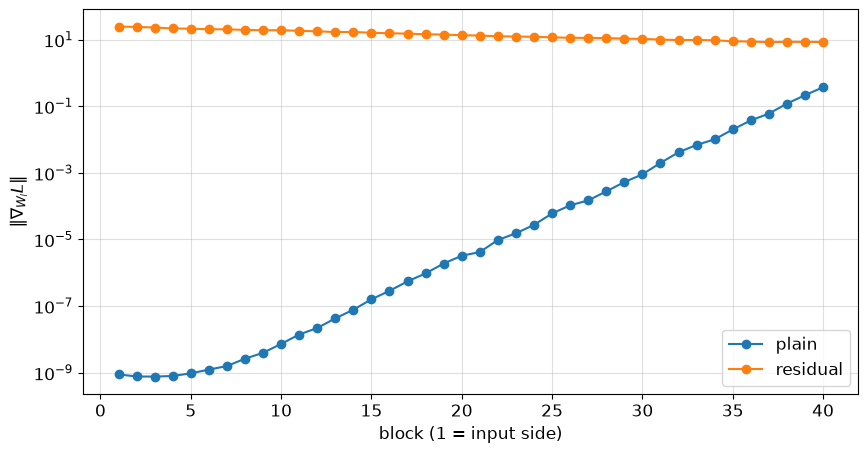

In [111]:
plt.figure(figsize=(10, 5))
for residual, label in [(False, 'plain'), (True, 'residual')]:
    plt.plot(range(1, 41), stack_grad_norms(residual), 'o-', label=label)
plt.yscale('log')
plt.xlabel('block (1 = input side)')
plt.ylabel(r'$\|\nabla_{W_l} L\|$')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

В plain-сети градиент до первых блоков фактически не доходит, в residual он того же порядка по всей глубине. Тот же приём — `x + Attention(x)`, `x + MLP(x)` — стоит в каждом блоке трансформера.

---
# 12. FashionMNIST и маленькая CNN

Пиксели в $[0, 1]$, без `Normalize`: $\varepsilon$ атаки измеряется прямо в единицах яркости.

In [93]:
FAST_MODE = True

N_TRAIN = 12_000 if FAST_MODE else 60_000
N_EPOCHS = 3 if FAST_MODE else 8
N_TEST = 2_000 if FAST_MODE else 10_000
N_ATTACK = 1_000 if FAST_MODE else 5_000
PGD_STEPS = 10 if FAST_MODE else 20
BATCH_SIZE = 128
DATA_ROOT = './data'

In [94]:
transform = transforms.ToTensor()   # PIL -> (1, 28, 28) в [0, 1]
train_full = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_full = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=transform)
CLASSES = train_full.classes
CLASSES

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [95]:
g = torch.Generator().manual_seed(0)
train_idx = torch.randperm(len(train_full), generator=g)[:N_TRAIN].tolist()
test_idx = torch.randperm(len(test_full), generator=g)[:N_TEST].tolist()

train_set = Subset(train_full, train_idx)
test_set = Subset(test_full, test_idx)
attack_set = Subset(test_full, test_idx[:N_ATTACK])
len(train_set), len(test_set), len(attack_set)

(12000, 2000, 1000)

In [96]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
test_loader = DataLoader(test_set, batch_size=500, shuffle=False)
attack_loader = DataLoader(attack_set, batch_size=250, shuffle=False)

x0, y0 = train_set[0]
x0.shape, x0.dtype, x0.min().item(), x0.max().item()

(torch.Size([1, 28, 28]), torch.float32, 0.0, 1.0)

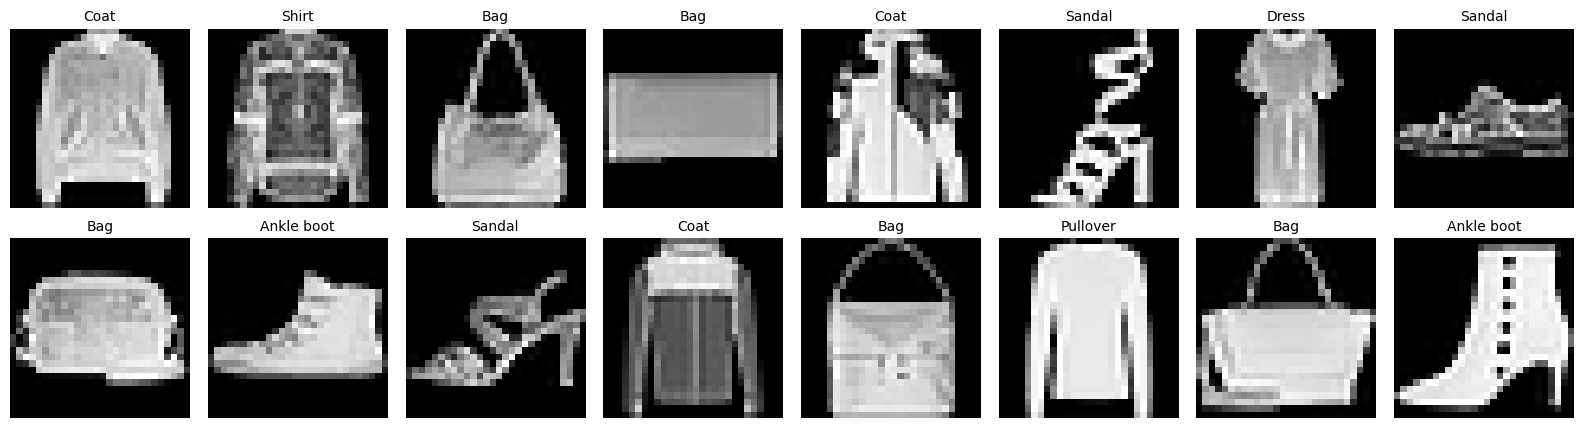

In [97]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, idx in zip(axes.flat, range(16)):
    img, label = test_set[idx]
    ax.imshow(img[0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(CLASSES[label], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [98]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # (32, 14, 14)
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # (64, 7, 7)
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


SmallCNN()

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Linear(in_features=3136, out_features=10, bias=True)
)

In [99]:
cnn_layers = [dict(k=3), dict(k=2, s=2), dict(k=3), dict(k=2, s=2)]
print('params:', sum(p.numel() for p in SmallCNN().parameters()))
print('receptive field of last feature map:', receptive_field(cnn_layers)[-1][0])

params: 50186
receptive field of last feature map: 10


In [100]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(loader.dataset)

In [101]:
set_seed(0)
model = SmallCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

start = time.time()
for epoch in range(N_EPOCHS):
    train_loss = train_epoch(model, train_loader, optimizer)
    print(f'epoch {epoch + 1}/{N_EPOCHS}: train loss = {train_loss:.4f}, test acc = {evaluate(model, test_loader):.4f}')
print(f'{time.time() - start:.1f} s on {device}')

epoch 1/3: train loss = 0.8795, test acc = 0.7735


epoch 2/3: train loss = 0.5053, test acc = 0.8245


epoch 3/3: train loss = 0.4267, test acc = 0.8480
6.9 s on mps


In [102]:
clean_acc = evaluate(model, test_loader)
assert clean_acc > 0.7

model.eval()
model.zero_grad(set_to_none=True)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

---
# 13. Adversarial examples

![panda -> gibbon](figures/adversarial_panda.png)

Goodfellow, Shlens, Szegedy, *Explaining and Harnessing Adversarial Examples*, 2014, рис. 1 (GoogLeNet, ImageNet). Изображение: TensorFlow tutorial [«Adversarial example using FGSM»](https://www.tensorflow.org/tutorials/generative/adversarial_fgsm), CC BY 4.0.

Возмущение с $\varepsilon = 0.007$ глазом не видно, но «panda» (57.7%) становится «gibbon» (99.3%). Ниже тот же приём на FashionMNIST: сначала градиент по входу, потом FGSM.

## 13.1 Градиент по входу

$$\nabla_\theta L(f_\theta(x), y) \quad\longrightarrow\quad \nabla_x L(f_\theta(x), y)$$

In [103]:
x_batch, y_batch = next(iter(attack_loader))
x_batch, y_batch = x_batch.to(device), y_batch.to(device)
x = x_batch[:8].clone().requires_grad_(True)   # x — лист графа
y = y_batch[:8]

In [104]:
loss = F.cross_entropy(model(x), y, reduction='sum')
grad_x, = torch.autograd.grad(loss, x)   # только по x, .grad параметров не трогаем
assert_no_param_grads(model)
grad_x.shape

torch.Size([8, 1, 28, 28])

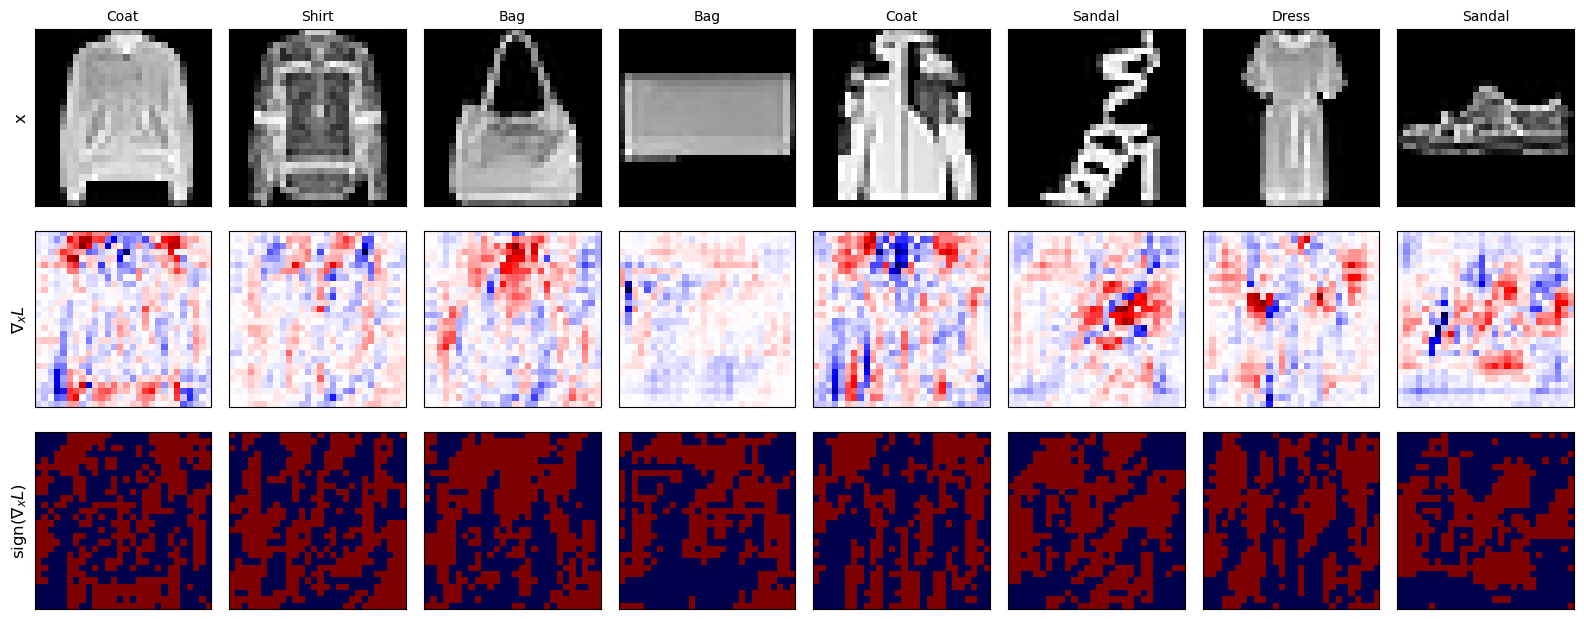

In [105]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    g = grad_x[i, 0].cpu()
    axes[0, i].imshow(x[i, 0].detach().cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(CLASSES[y[i]], fontsize=10)
    axes[1, i].imshow(g, cmap='seismic', vmin=-g.abs().max(), vmax=g.abs().max())
    axes[2, i].imshow(g.sign(), cmap='seismic', vmin=-1, vmax=1)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x', r'$\nabla_x L$', r'sign$(\nabla_x L)$']):
    ax.set_ylabel(label, fontsize=12)
plt.tight_layout()
plt.show()

Градиент не похож на аккуратную карту «важных» пикселей: он шумный и заметен даже на фоне. Модель чувствительна к изменениям, которые человек счёл бы несущественными, — это и использует атака.

---
# 14. FGSM: Fast Gradient Sign Method

Хотим найти маленькое возмущение $\delta$, которое сильнее всего увеличит loss:
$$
\max_{\|\delta\|_\infty \le \varepsilon} L\big(f(x + \delta), y\big).
$$
$\|\delta\|_\infty \le \varepsilon$ означает, что каждый пиксель меняется не больше чем на $\varepsilon$.

Линеаризуем loss около $x$:
$$
L(x + \delta) \approx L(x) + \nabla_x L(x)^\top \delta = L(x) + \sum_i g_i \delta_i.
$$

Линейная функция на кубе $|\delta_i| \le \varepsilon$ максимизируется **покоординатно**: каждое $\delta_i$ ставим на границу в сторону знака $g_i$:
$$
\delta^* = \varepsilon\, \mathrm{sign}(\nabla_x L), \qquad
\max = \varepsilon \|\nabla_x L\|_1.
$$

Получаем
$$
x_{\mathrm{adv}} = \mathrm{clip}_{[0,1]}\left(x + \varepsilon\, \mathrm{sign}(\nabla_x L(f(x), y))\right).
$$

Один backward — и атака готова.

In [106]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():                      # работает и внутри no_grad
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
    x_adv = x + eps * grad.sign()
    return x_adv.clamp(0, 1).detach()

In [107]:
eps = 0.1
x, y = x_batch, y_batch
x_fgsm = fgsm_attack(model, x, y, eps)

tol = 1e-6
assert (x_fgsm - x).abs().amax() <= eps + tol   # внутри L_inf шара
assert x_fgsm.min() >= 0 and x_fgsm.max() <= 1  # валидная картинка
assert not x_fgsm.requires_grad
assert_no_param_grads(model)

In [108]:
@torch.no_grad()
def batch_accuracy(model, x, y):
    return (model(x).argmax(1) == y).float().mean().item()


batch_accuracy(model, x, y), batch_accuracy(model, x_fgsm, y)

(0.8320000171661377, 0.24799999594688416)

### Визуализация атаки

In [109]:
@torch.no_grad()
def top_prediction(model, x):
    prob, cls = F.softmax(model(x), dim=1).max(dim=1)
    return prob.cpu(), cls.cpu()


def plot_row(axes_row, images, titles=None, colors=None, **imshow_kwargs):
    for k, ax in enumerate(axes_row):
        ax.imshow(images[k, 0].detach().cpu(), **imshow_kwargs)
        if titles is not None:
            ax.set_title(titles[k], fontsize=9, color=colors[k] if colors else 'black')
        ax.set_xticks([])
        ax.set_yticks([])

In [110]:
def show_attack(model, x, y, x_adv, eps, n=8):
    p_clean, c_clean = top_prediction(model, x[:n])
    p_adv, c_adv = top_prediction(model, x_adv[:n])
    y = y[:n].cpu()

    fig, axes = plt.subplots(3, n, figsize=(2.1 * n, 7.8))
    plot_row(axes[0], x, [f'true: {CLASSES[t]}\npred: {CLASSES[c]} ({p:.2f})' for t, c, p in zip(y, c_clean, p_clean)],
             cmap='gray', vmin=0, vmax=1)
    plot_row(axes[1], x_adv - x, cmap='seismic', vmin=-eps, vmax=eps)
    plot_row(axes[2], x_adv, [f'pred: {CLASSES[c]} ({p:.2f})' for c, p in zip(c_adv, p_adv)],
             colors=['red' if c != t else 'green' for c, t in zip(c_adv, y)], cmap='gray', vmin=0, vmax=1)
    for ax, label in zip(axes[:, 0], ['original', 'perturbation\n(scaled to [-ε, ε])', 'adversarial']):
        ax.set_ylabel(label, fontsize=11)
    plt.tight_layout()
    plt.show()

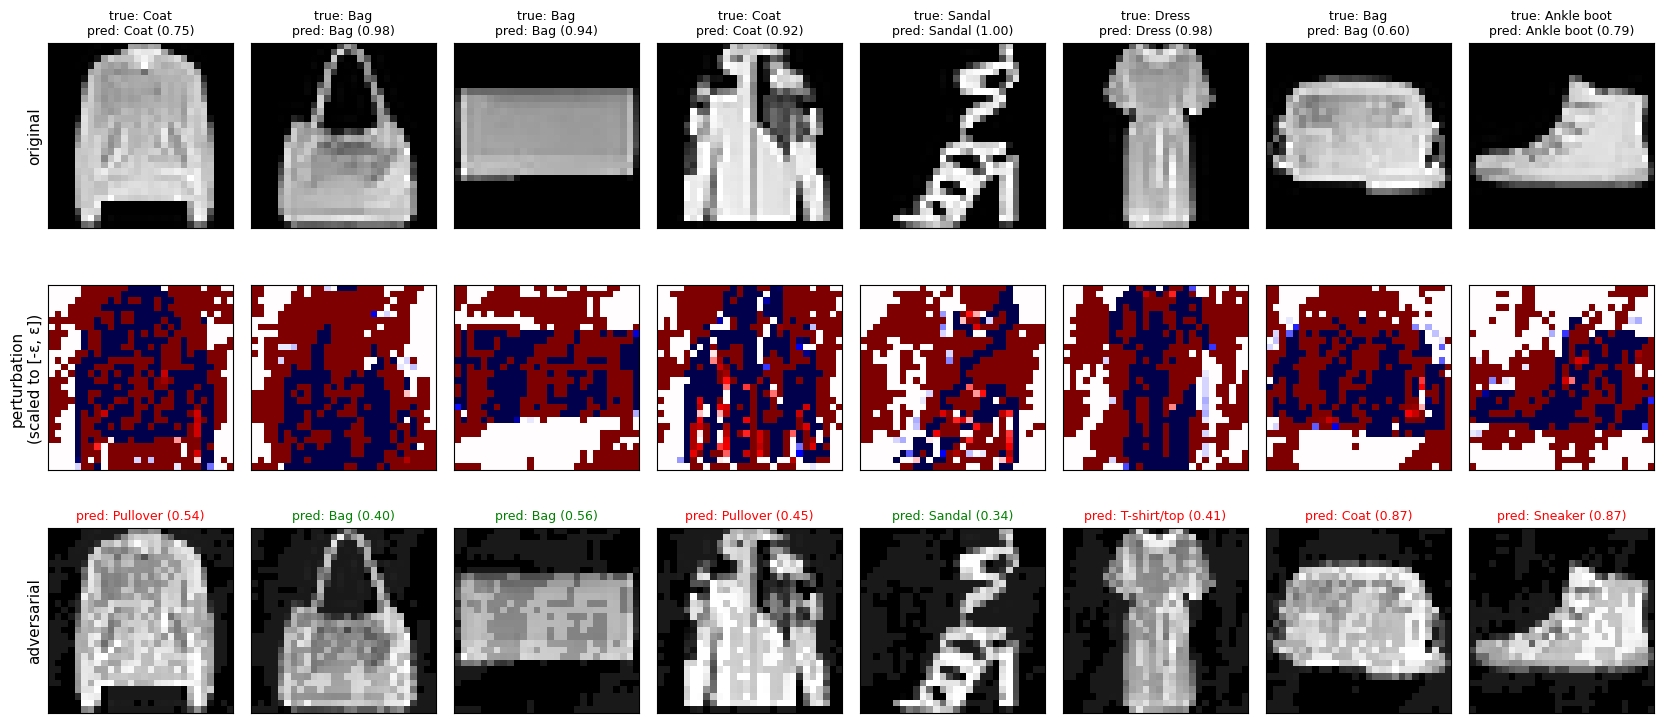

In [111]:
correct = model(x).argmax(1) == y
x_correct, y_correct = x[correct], y[correct]
show_attack(model, x_correct, y_correct, fgsm_attack(model, x_correct, y_correct, eps), eps)

Каждый пиксель сдвинут ровно на $\pm\varepsilon$. Исключение — белые области на фоне: пиксель уже равен 0, градиент просил сделать его темнее, и `clamp` обрезал сдвиг.

---
# 15. Accuracy от $\varepsilon$

$$\varepsilon \longmapsto \mathrm{accuracy}(\varepsilon)$$

In [112]:
def evaluate_attack(model, loader, attack, **attack_kwargs):
    model.eval()
    correct = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        x_adv = attack(model, x, y, **attack_kwargs)   # здесь нужен градиент по x
        with torch.no_grad():
            correct += (model(x_adv).argmax(dim=1) == y).sum().item()
    return correct / len(loader.dataset)


def evaluate_fgsm(model, loader, eps):
    return evaluate_attack(model, loader, fgsm_attack, eps=eps)


evaluate_fgsm(model, attack_loader, eps=0.1)

0.225

In [113]:
epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
fgsm_accs = [evaluate_fgsm(model, attack_loader, e) for e in epsilons]

assert abs(fgsm_accs[0] - evaluate(model, attack_loader)) < 1e-9   # eps = 0 — clean accuracy
assert_no_param_grads(model)
dict(zip(epsilons, fgsm_accs))

{0.0: 0.855,
 0.02: 0.735,
 0.05: 0.523,
 0.1: 0.225,
 0.15: 0.095,
 0.2: 0.039,
 0.3: 0.001}

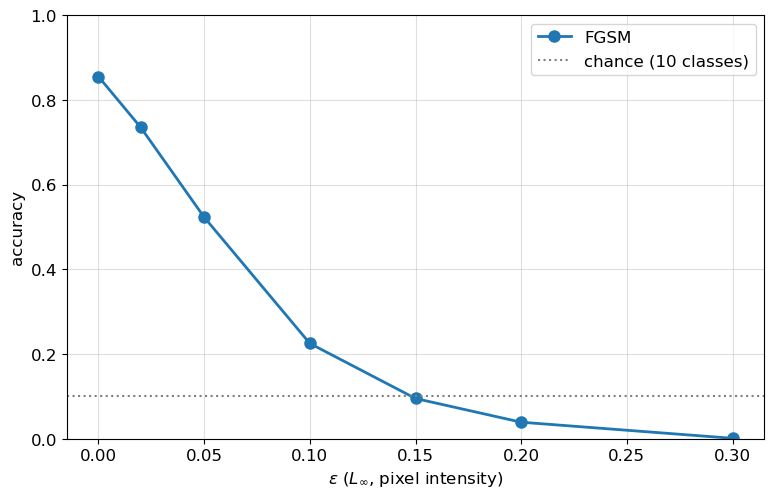

In [114]:
plt.figure(figsize=(9, 5.5))
plt.plot(epsilons, fgsm_accs, 'o-', linewidth=2, markersize=8, label='FGSM')
plt.axhline(0.1, color='gray', linestyle=':', label='chance (10 classes)')
plt.xlabel(r'$\varepsilon$ ($L_\infty$, pixel intensity)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

При больших $\varepsilon$ accuracy опускается ниже случайного угадывания: атака не добавляет шум, а целенаправленно уводит предсказание от правильного класса.

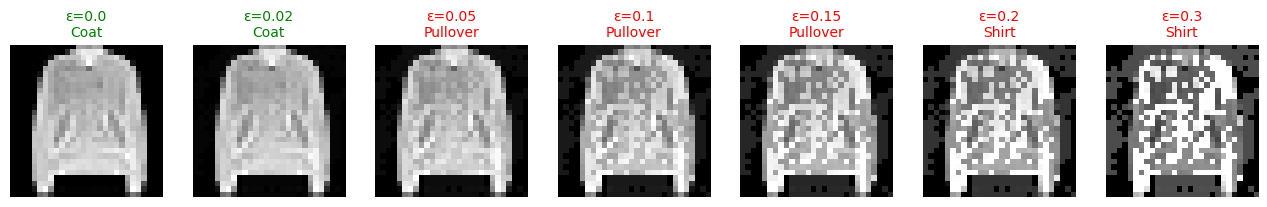

In [115]:
img, label = x_correct[:1], y_correct[:1]
fig, axes = plt.subplots(1, len(epsilons), figsize=(2.3 * len(epsilons), 3))
for ax, e in zip(axes, epsilons):
    x_e = fgsm_attack(model, img, label, e)
    _, pred = top_prediction(model, x_e)
    ax.imshow(x_e[0, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'ε={e}\n{CLASSES[pred.item()]}', fontsize=10,
                 color='green' if pred.item() == label.item() else 'red')
    ax.axis('off')
plt.show()

---
# 16. PGD: Projected Gradient Descent

FGSM делает **один** шаг по линейному приближению. Но loss нейросети нелинеен: после шага градиент может смотреть совсем в другую сторону. Естественное улучшение — делать много маленьких шагов и каждый раз пересчитывать градиент:
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} + \alpha\, \mathrm{sign}\,\nabla_x L\big(f(x^{(k)}), y\big)\Big],
$$
где $\Pi$ — **проекция** обратно в допустимое множество
$$B_\infty(x, \varepsilon) = \{x' : \|x' - x\|_\infty \le \varepsilon\} \cap [0, 1]^d.$$

Без проекции после $k$ шагов размера $\alpha$ возмущение могло бы вырасти до $k\alpha > \varepsilon$. Для $L_\infty$ проекция — просто покоординатная обрезка:
$$\Pi(x')_i = \mathrm{clip}\big(x'_i,\; x_i - \varepsilon,\; x_i + \varepsilon\big),$$
а потом ещё `clamp(0, 1)`.

**Random start**: начинаем не из $x$, а из случайной точки внутри шара, $x^{(0)} = x + \mathrm{U}(-\varepsilon, \varepsilon)^d$. Это помогает уйти от точки, где градиент малоинформативен, и позволяет делать restarts.

Обычный выбор шага: $\alpha \approx 2.5\,\varepsilon / \text{steps}$, чтобы за время атаки можно было дойти от одного края шара до другого.

![PGD 2D](figures/pgd_2d.gif)

Игрушечный loss на плоскости. Пунктир — шаг ascent, точки — проекция обратно в шар: $L_\infty$ — квадрат (clip), $L_2$ — круг (масштабирование). FGSM, линеаризуя loss в $x$, уходит в угол с $L = -5.02$; PGD, пересчитывая градиент, находит точку с $L \approx -1.67$.

In [116]:
def pgd_attack(model, x, y, eps, alpha, steps, random_start=True, loss_history=None):
    x = x.detach()
    if random_start:
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    else:
        x_adv = x.clone()

    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            loss = F.cross_entropy(model(x_adv), y)
            grad, = torch.autograd.grad(loss, x_adv)
        if loss_history is not None:
            loss_history.append(loss.item())

        x_adv = x_adv.detach() + alpha * grad.sign()           # шаг ascent
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps)   # проекция на L_inf шар
        x_adv = x_adv.clamp(0, 1)                               # проекция на [0, 1]
    return x_adv.detach()

In [117]:
steps = 20
alpha = 2.5 * eps / steps
torch.manual_seed(0)
x_pgd = pgd_attack(model, x, y, eps=eps, alpha=alpha, steps=steps)

assert (x_pgd - x).abs().amax() <= eps + tol
assert x_pgd.min() >= 0 and x_pgd.max() <= 1
assert not x_pgd.requires_grad
assert_no_param_grads(model)

In [118]:
{'clean': batch_accuracy(model, x, y),
 'FGSM': batch_accuracy(model, x_fgsm, y),
 f'PGD-{steps}': batch_accuracy(model, x_pgd, y)}

{'clean': 0.8320000171661377,
 'FGSM': 0.24799999594688416,
 'PGD-20': 0.14000000059604645}

In [119]:
with torch.no_grad():
    loss_clean = F.cross_entropy(model(x), y).item()
    loss_fgsm = F.cross_entropy(model(x_fgsm), y).item()

pgd_histories = []
for seed in range(3):
    torch.manual_seed(seed)
    history = []
    pgd_attack(model, x, y, eps=eps, alpha=alpha, steps=40, loss_history=history)
    pgd_histories.append(history)

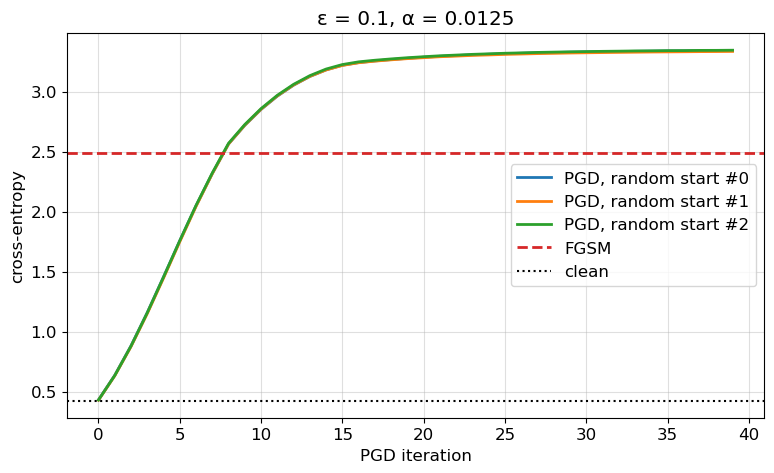

In [120]:
plt.figure(figsize=(9, 5))
for seed, history in enumerate(pgd_histories):
    plt.plot(history, linewidth=2, label=f'PGD, random start #{seed}')
plt.axhline(loss_fgsm, color='tab:red', linestyle='--', linewidth=2, label='FGSM')
plt.axhline(loss_clean, color='k', linestyle=':', label='clean')
plt.xlabel('PGD iteration')
plt.ylabel('cross-entropy')
plt.title(f'ε = {eps}, α = {alpha:.4f}')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Loss под PGD растёт и через несколько итераций обгоняет FGSM. Кривые для разных random start почти совпадают: для этой модели стартовая точка почти не важна.

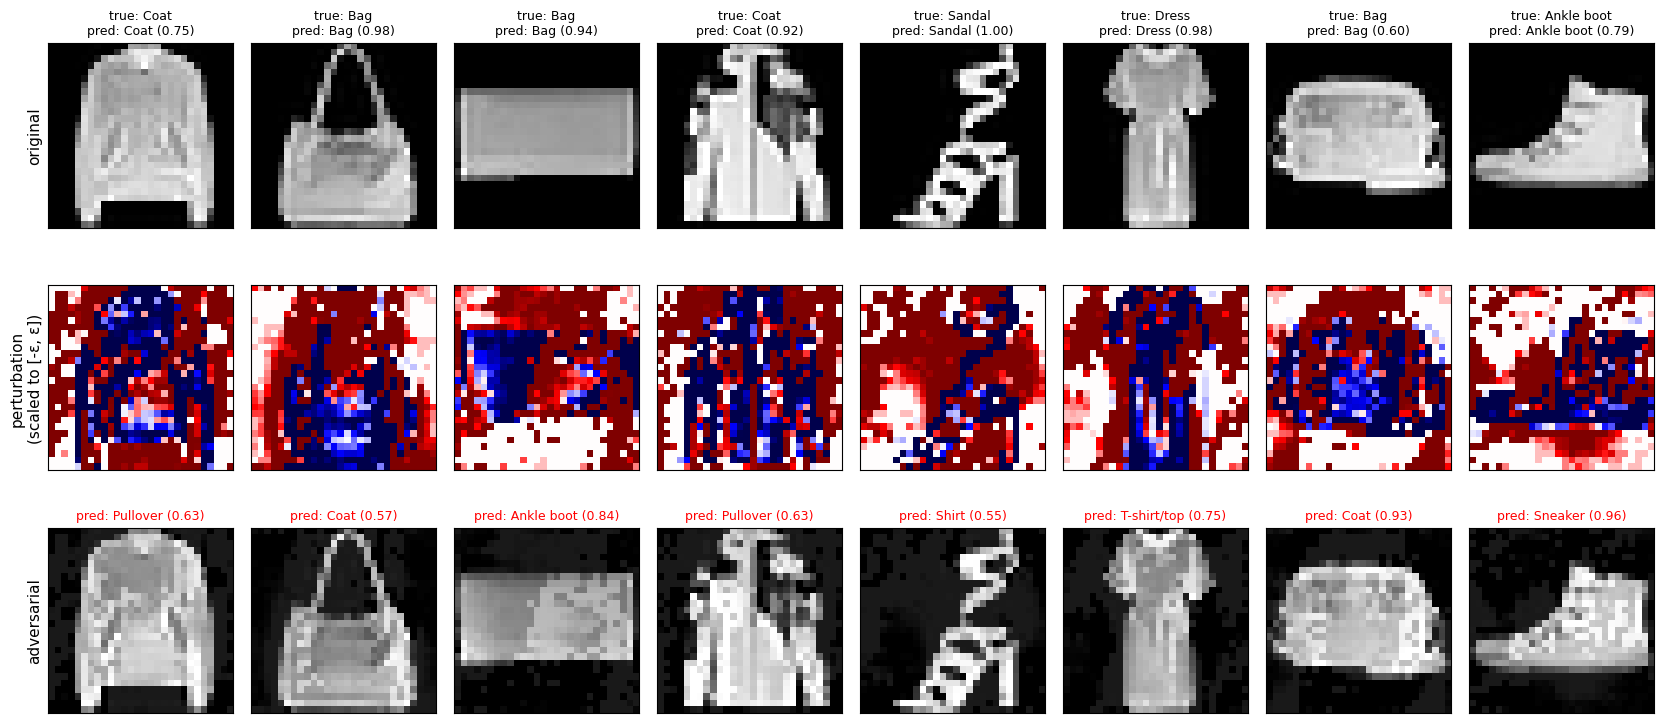

In [121]:
show_attack(model, x_correct, y_correct,
            pgd_attack(model, x_correct, y_correct, eps=eps, alpha=alpha, steps=steps), eps)

### PGD по шагам

In [122]:
def pgd_trajectory(model, x, y, steps):
    # x^(0), ..., x^(steps): одинаковый random start, поэтому это префиксы одной траектории
    frames = []
    for k in range(steps + 1):
        torch.manual_seed(0)
        frames.append(pgd_attack(model, x, y, eps=eps, alpha=alpha, steps=k))
    return torch.cat(frames)   # (steps + 1, 1, 28, 28)


for idx in range(len(x_correct)):   # первая картинка, которую PGD обманывает
    pgd_frames = pgd_trajectory(model, x_correct[idx:idx + 1], y_correct[idx:idx + 1], steps)
    if top_prediction(model, pgd_frames[-1:])[1].item() != y_correct[idx].item():
        break
idx, CLASSES[y_correct[idx]]

(0, 'Coat')

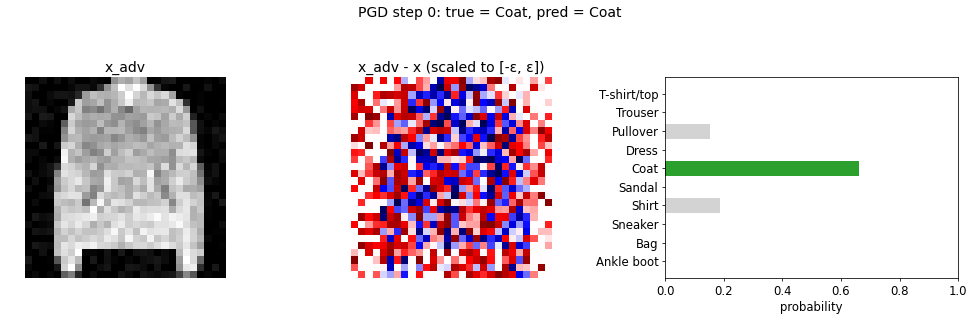

In [123]:
def animate_pgd(model, x, y, frames_x, path, fps=4):
    with torch.no_grad():
        probs = F.softmax(model(frames_x), dim=1).cpu()
    true = y.item()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.3]})

    def update(k):
        for ax in axes:
            ax.clear()
        pred = probs[k].argmax().item()
        axes[0].imshow(frames_x[k, 0].cpu(), cmap='gray', vmin=0, vmax=1)
        axes[0].set_title('x_adv')
        axes[1].imshow((frames_x[k] - x[0])[0].cpu(), cmap='seismic', vmin=-eps, vmax=eps)
        axes[1].set_title('x_adv - x (scaled to [-ε, ε])')
        for ax in axes[:2]:
            ax.axis('off')
        colors = ['tab:green' if c == true else 'tab:red' if c == pred else 'lightgray' for c in range(10)]
        axes[2].barh(CLASSES, probs[k], color=colors)
        axes[2].set_xlim(0, 1)
        axes[2].invert_yaxis()
        axes[2].set_xlabel('probability')
        fig.suptitle(f'PGD step {k}: true = {CLASSES[true]}, pred = {CLASSES[pred]}')
        fig.tight_layout(rect=(0, 0, 1, 0.93), w_pad=3)

    frames = list(range(len(frames_x))) + [len(frames_x) - 1] * (2 * fps)
    FuncAnimation(fig, update, frames=frames).save(path, writer=PillowWriter(fps=fps), dpi=70)
    plt.close(fig)
    return Image(filename=path)


animate_pgd(model, x_correct[idx:idx + 1], y_correct[idx], pgd_frames, 'pgd_steps.gif')

---
# 17. FGSM vs PGD

In [124]:
def evaluate_pgd(model, loader, eps, steps=PGD_STEPS):
    if eps == 0:
        return evaluate(model, loader)
    return evaluate_attack(model, loader, pgd_attack, eps=eps, alpha=2.5 * eps / steps, steps=steps)


torch.manual_seed(0)
pgd_accs = [evaluate_pgd(model, attack_loader, e) for e in epsilons]
assert_no_param_grads(model)

print(f'{"eps":<6}{"FGSM":>8}{"PGD-" + str(PGD_STEPS):>8}')
for e, acc_f, acc_p in zip(epsilons, fgsm_accs, pgd_accs):
    print(f'{e:<6}{acc_f:>8.3f}{acc_p:>8.3f}')

eps       FGSM  PGD-10
0.0      0.855   0.855
0.02     0.735   0.728
0.05     0.523   0.474
0.1      0.225   0.133
0.15     0.095   0.048
0.2      0.039   0.016
0.3      0.001   0.000


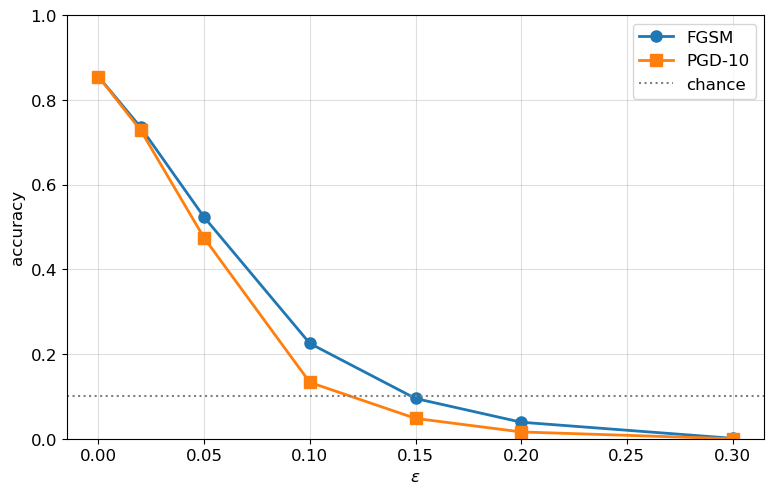

In [125]:
plt.figure(figsize=(9, 5.5))
plt.plot(epsilons, fgsm_accs, 'o-', linewidth=2, markersize=8, label='FGSM')
plt.plot(epsilons, pgd_accs, 's-', linewidth=2, markersize=8, label=f'PGD-{PGD_STEPS}')
plt.axhline(0.1, color='gray', linestyle=':', label='chance')
plt.xlabel(r'$\varepsilon$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

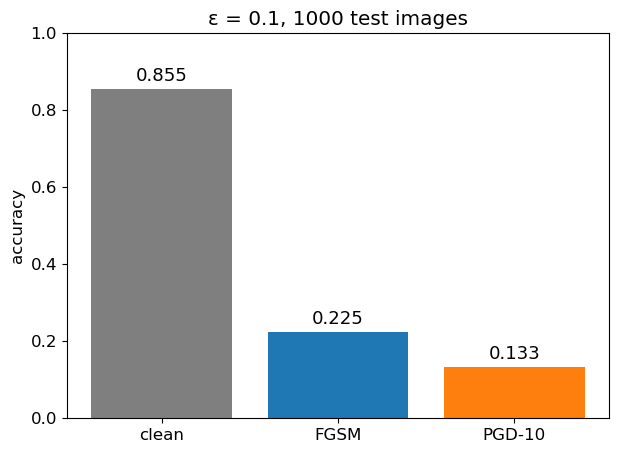

In [126]:
i_eps = epsilons.index(0.1)
bars = {'clean': fgsm_accs[0], 'FGSM': fgsm_accs[i_eps], f'PGD-{PGD_STEPS}': pgd_accs[i_eps]}

plt.figure(figsize=(7, 5))
plt.bar(bars.keys(), bars.values(), color=['tab:gray', 'tab:blue', 'tab:orange'])
for k, v in enumerate(bars.values()):
    plt.text(k, v + 0.02, f'{v:.3f}', ha='center', fontsize=13)
plt.ylim(0, 1)
plt.ylabel('accuracy')
plt.title(f'ε = 0.1, {len(attack_set)} test images')
plt.show()

FGSM — один шаг по линейному приближению loss. PGD многократно пересчитывает градиент и проецирует обратно в допустимое множество, поэтому при том же $\varepsilon$ обычно сильнее. Но PGD — тоже локальная эвристика: его accuracy — **верхняя** оценка настоящей robust accuracy.

---
# 18. \*Атака одним пикселем ($L_0$)

До сих пор ограничение было $\|\delta\|_\infty \le \varepsilon$: меняем **все** пиксели, но чуть-чуть. Противоположный режим — менять **мало** пикселей, но как угодно сильно:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big),
\qquad \|\delta\|_0 = \#\{i : \delta_i \ne 0\}.
$$

При $k = 1$ и картинке $28 \times 28$ кандидатов мало: 784 позиции × значение пикселя. Возьмём крайние значения $v \in \{0, 1\}$ — это $2 \cdot 784 = 1568$ картинок, **один батч**. Среди них выбираем кандидата с максимальным margin
$$m = \max_{c \ne y} z_c - z_y,$$
модель обманута $\iff m > 0$. Перебор даёт точный ответ на этой сетке значений.

In [127]:
def one_pixel_candidates(x):
    # x: (1, 28, 28) -> (2d, 1, 28, 28): каждый пиксель по очереди = 0, затем = 1
    d = x.numel()
    cand = x.expand(2 * d, *x.shape).clone()
    flat = cand.view(2 * d, d)
    idx = torch.arange(d, device=x.device)
    flat[idx, idx] = 0.0
    flat[d + idx, idx] = 1.0
    return cand


cand = one_pixel_candidates(x_correct[0])
assert ((cand - x_correct[0]).flatten(1) != 0).sum(1).max() <= 1   # ||delta||_0 <= 1
cand.shape

torch.Size([1568, 1, 28, 28])

In [128]:
@torch.no_grad()
def margins(model, x, y):
    # max_{c != y} z_c - z_y; > 0 <=> модель ошиблась
    logits = model(x)
    true = logits.gather(1, y[:, None]).squeeze(1)
    other = logits.scatter(1, y[:, None], float('-inf')).amax(dim=1)
    return other - true


def one_pixel_exhaustive(model, x, y):
    # x: (1, 28, 28), y: () -> лучший из 1568 кандидатов
    cand = one_pixel_candidates(x)
    return cand[margins(model, cand, y.expand(len(cand))).argmax()]


m = margins(model, cand, y_correct[0].expand(len(cand)))
print(f'candidates that fool the model: {(m > 0).sum().item()} / {len(cand)}')

candidates that fool the model: 0 / 1568


### Линеаризация

Как и в FGSM, заменим loss линейным приближением. Изменить пиксель $i$ можно максимум до $0$ или до $1$:
$$
L(x + \delta) - L(x) \approx g_i\,(v - x_i), \qquad
\max_{v \in [0,1]} g_i (v - x_i) = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big) =: \mathrm{gain}_i.
$$

Берём $i^* = \arg\max_i \mathrm{gain}_i$ — один backward вместо 1568 forward.

In [129]:
def one_pixel_gradient(model, x, y):
    # x: (B, 1, 28, 28) -> в каждой картинке меняется один пиксель
    x = x.detach()
    x_req = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_req), y, reduction='sum'), x_req)
    gain = torch.maximum(grad * (1 - x), -grad * x).flatten(1)   # (B, d)
    idx = gain.argmax(dim=1, keepdim=True)
    new_val = (grad.flatten(1).gather(1, idx) > 0).float()        # 1, если loss растёт с яркостью
    return x.flatten(1).scatter(1, idx, new_val).view_as(x)

In [130]:
N_ONE_PIXEL = 100 if FAST_MODE else 500
x_pool, y_pool = [], []
with torch.no_grad():
    for xb, yb in attack_loader:
        xb, yb = xb.to(device), yb.to(device)
        keep = model(xb).argmax(1) == yb       # только верно классифицированные
        x_pool.append(xb[keep])
        y_pool.append(yb[keep])
x_pool, y_pool = torch.cat(x_pool)[:N_ONE_PIXEL], torch.cat(y_pool)[:N_ONE_PIXEL]
x_pool.shape

torch.Size([100, 1, 28, 28])

In [131]:
start = time.time()
x_exh = torch.stack([one_pixel_exhaustive(model, xi, yi) for xi, yi in zip(x_pool, y_pool)])
print(f'exhaustive: {time.time() - start:.1f} s for {len(x_pool)} images x {2 * 28 * 28} candidates')

x_grad1 = one_pixel_gradient(model, x_pool, y_pool)
assert ((x_grad1 - x_pool).flatten(1) != 0).sum(1).max() <= 1

print(f'fooled by 1 pixel, exhaustive: {1 - batch_accuracy(model, x_exh, y_pool):.3f}')
print(f'fooled by 1 pixel, gradient:   {1 - batch_accuracy(model, x_grad1, y_pool):.3f}')

exhaustive: 3.7 s for 100 images x 1568 candidates
fooled by 1 pixel, exhaustive: 0.080
fooled by 1 pixel, gradient:   0.030


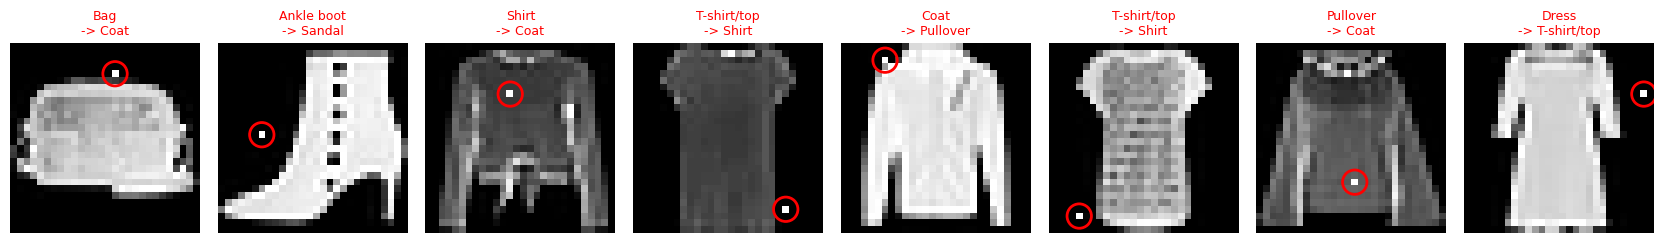

In [132]:
def show_one_pixel(model, x, x_adv, y, n=8):
    _, c_adv = top_prediction(model, x_adv[:n])
    fig, axes = plt.subplots(1, n, figsize=(2.1 * n, 3))
    for k, ax in enumerate(axes):
        r, c = divmod(((x_adv[k] - x[k]).flatten() != 0).nonzero()[0].item(), 28)
        ax.imshow(x_adv[k, 0].cpu(), cmap='gray', vmin=0, vmax=1)
        ax.add_patch(plt.Circle((c, r), 1.8, fill=False, edgecolor='red', linewidth=2))
        ax.set_title(f'{CLASSES[y[k]]}\n-> {CLASSES[c_adv[k]]}', fontsize=9,
                     color='red' if c_adv[k] != y[k].item() else 'green')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


with torch.no_grad():
    fooled_mask = model(x_exh).argmax(1) != y_pool
show_one_pixel(model, x_pool[fooled_mask], x_exh[fooled_mask], y_pool[fooled_mask])

### $k$ пикселей: жадная атака

На каждом шаге пересчитываем градиент и меняем ещё один пиксель с максимальным $\mathrm{gain}_i$ среди нетронутых:
$$\|x_{\mathrm{adv}} - x\|_0 \le k.$$

In [133]:
def greedy_pixel_attack(model, x, y, k):
    x_adv = x.detach().clone()
    changed = torch.zeros_like(x_adv, dtype=torch.bool)
    for _ in range(k):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
        x_adv = x_adv.detach()
        gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -1.0)
        idx = gain.flatten(1).argmax(dim=1, keepdim=True)                        # (B, 1)
        new_val = (grad.flatten(1).gather(1, idx) > 0).float()
        x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
        changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
    return x_adv


x_k = greedy_pixel_attack(model, x_pool, y_pool, k=10)
assert ((x_k - x_pool).flatten(1) != 0).sum(1).max() <= 10
batch_accuracy(model, x_k, y_pool)

0.5799999833106995

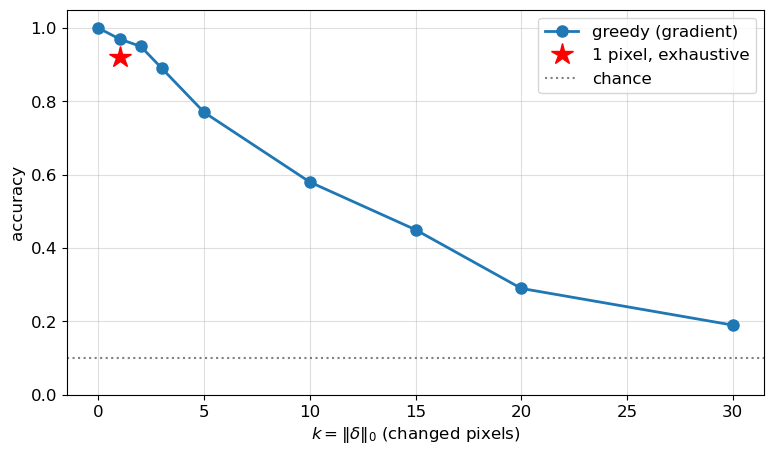

In [134]:
ks = [0, 1, 2, 3, 5, 10, 15, 20, 30]
greedy_accs = [batch_accuracy(model, greedy_pixel_attack(model, x_pool, y_pool, k), y_pool) for k in ks]

plt.figure(figsize=(9, 5))
plt.plot(ks, greedy_accs, 'o-', linewidth=2, markersize=8, label='greedy (gradient)')
plt.plot([1], [batch_accuracy(model, x_exh, y_pool)], 'r*', markersize=16, label='1 pixel, exhaustive')
plt.axhline(0.1, color='gray', linestyle=':', label='chance')
plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
plt.ylabel('accuracy')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

---
# 19. \*Adversarial training

$$
\min_\theta \; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big]
$$

Внутренний max — атака, внешний min — шаг оптимизатора:
$$L_{\text{train}} = \tfrac12 L\big(f(x), y\big) + \tfrac12 L\big(f(x_{\text{FGSM}}), y\big)$$

In [135]:
def adversarial_finetune(model, loader, eps, epochs=1, lr=5e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            model.eval()                          # атака — в режиме инференса
            x_adv = fgsm_attack(model, x, y, eps)
            model.train()
            loss = 0.5 * F.cross_entropy(model(x), y) + 0.5 * F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    model.zero_grad(set_to_none=True)
    return model

In [136]:
EPS_TRAIN = 0.1
set_seed(0)
start = time.time()
robust_model = adversarial_finetune(copy.deepcopy(model), train_loader, EPS_TRAIN,
                                    epochs=2 if FAST_MODE else 5)
print(f'{time.time() - start:.1f} s')

8.1 s


In [137]:
torch.manual_seed(0)
robustness = {}
for name, m in [('standard', model), ('FGSM-trained', robust_model)]:
    robustness[name] = [evaluate(m, attack_loader),
                        evaluate_fgsm(m, attack_loader, EPS_TRAIN),
                        evaluate_pgd(m, attack_loader, EPS_TRAIN)]

print(f'{"model":<14}{"clean":>8}{"FGSM":>8}{"PGD-" + str(PGD_STEPS):>8}')
for name, accs in robustness.items():
    print(f'{name:<14}' + ''.join(f'{a:>8.3f}' for a in accs))

model            clean    FGSM  PGD-10
standard         0.855   0.225   0.132
FGSM-trained     0.834   0.557   0.471


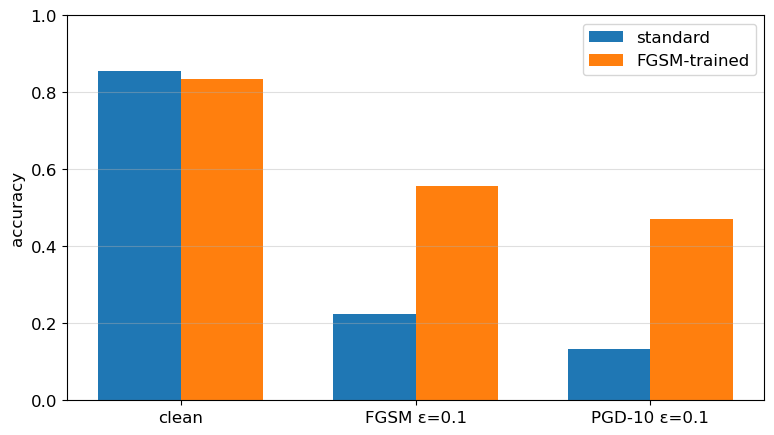

In [138]:
plt.figure(figsize=(9, 5))
width = 0.35
for k, (name, accs) in enumerate(robustness.items()):
    plt.bar(np.arange(3) + (k - 0.5) * width, accs, width, label=name)
plt.xticks(range(3), ['clean', f'FGSM ε={EPS_TRAIN}', f'PGD-{PGD_STEPS} ε={EPS_TRAIN}'])
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, axis='y', alpha=0.4)
plt.show()

Robustness растёт, clean accuracy немного падает. Смотреть надо на PGD, а не только на FGSM: модель, обученная на FGSM, может научиться ломать именно линейное приближение (*gradient masking*).